# Intelligent Predictive Maintenance & Machine Failure Risk Management

## 1. Problem Statement

Unexpected machine failures in manufacturing industries can interrupt production, increase maintenance costs, delay deliveries, and reduce operational efficiency.

Traditional preventive maintenance relies on fixed schedules, which may result in unnecessary servicing or unexpected failures between inspections.

To address this challenge, we propose an **AI-powered Predictive Maintenance System** that analyzes historical machine operating conditions to predict potential failures and support proactive maintenance decisions.

## 2. Business Objectives

- Predict potential machine failures using operational data.
- Identify machine conditions associated with failures.
- Develop and compare traditional ML and ANN models.
- Minimize missed failures while controlling unnecessary inspections.
- Support maintenance teams through data-driven risk prioritization.

## 3. CBIM Approach – Context, Business, Implementation and Measurement

### C – Context
Understand manufacturing challenges, including unexpected machine failures, production interruptions, and increasing maintenance costs.

### B – Business
Define the business objective of predicting machine failures early, reducing downtime risks, and improving maintenance planning.

### I – Implementation
Develop an end-to-end solution using the AI4I 2020 dataset through:
- Data understanding, quality assessment, and EDA.
- Data preprocessing and feature engineering.
- Logistic Regression, Random Forest, and ANN development.
- Model comparison and controlled experimentation.
- Failure-risk classification and maintenance prioritization.

### M – Measurement
Evaluate model reliability using Precision, Recall, F1-score, ROC-AUC, PR-AUC, and Confusion Matrix.

Special attention will be given to **Recall**, as missing an actual machine failure can result in unexpected production downtime.

## 4. Dataset Overview

- Dataset: AI4I 2020 Predictive Maintenance Dataset
- Records: 10,000
- Columns: 14
- Problem Type: Binary Classification
- Target: `Machine failure` (0 = No Failure, 1 = Failure)

Identifier columns (`UDI`, `Product ID`) and failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) will be excluded from model inputs to prevent data leakage.

Dataset Source: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

## 5. Expected Outcome

Develop a reliable and reproducible predictive maintenance solution that identifies potential machine failures, compares ML and ANN performance, and recommends an appropriate model to support proactive maintenance and improve manufacturing efficiency.

# Phase 1 — Business Understanding, Data Audit and Preparation

In [1]:
# Purpose: Import the required libraries and load the predictive maintenance dataset.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ai4i2020.csv")

# Display the dataset
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 1. Dataset Overview

The AI4I 2020 Predictive Maintenance Dataset is used to develop a machine failure prediction system for manufacturing operations.

The dataset contains 10,000 records and 14 columns, including machine operating conditions, product information, a binary machine failure target, and five failure-mode indicators.

The objective is to identify patterns in machine operating conditions and predict potential failures before they occur.

**Target Variable:** `Machine failure`
- 0 – No machine failure
- 1 – Machine failure

**Important consideration:** UDI and Product ID are identifiers, while TWF, HDF, PWF, OSF, and RNF are failure-mode indicators. These columns will be excluded from model training to prevent data leakage.

In [2]:
# Purpose: Inspect dataset dimensions, column names, data types, and sample records.

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (10000, 14)

Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Initial Dataset Inspection

The dataset contains **10,000 records and 14 columns**, representing machine operating conditions, product information, and failure indicators.

The initial inspection reveals:

- 3 numerical columns with `float64` data type.
- 9 integer columns with `int64` data type.
- 2 categorical columns with `object` data type.
- All 10,000 records contain non-null values across all columns.
- The dataset occupies approximately 1.1 MB of memory.

The dataset contains both numerical and categorical features, which will require appropriate preprocessing before model development.

**Note:** Although no missing values are observed in this initial inspection, we will perform additional data-quality checks, including duplicate records, target imbalance, and unusual values.

In [3]:
# Checking data quality

# Purpose: Identify missing values, duplicate records, and duplicate columns.

print("Missing Values:")
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nDuplicate Column Names:", df.columns.duplicated().sum())

Missing Values:


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


Total Missing Values: 0

Duplicate Records: 0

Duplicate Column Names: 0


## 3. Data Quality Assessment

The initial data-quality assessment confirms that:

- **Missing Values:** No missing values were identified across the 14 columns.
- **Duplicate Records:** No duplicate rows were found.
- **Duplicate Columns:** No duplicate column names were detected.

The dataset appears structurally clean, so no missing-value imputation or duplicate removal is required at this stage.

However, further validation is necessary to identify potential outliers, unusual values, class imbalance, and possible data leakage before model development.

,Count,Percentage
Machine failure,,
0,9661,96.61
1,339,3.39


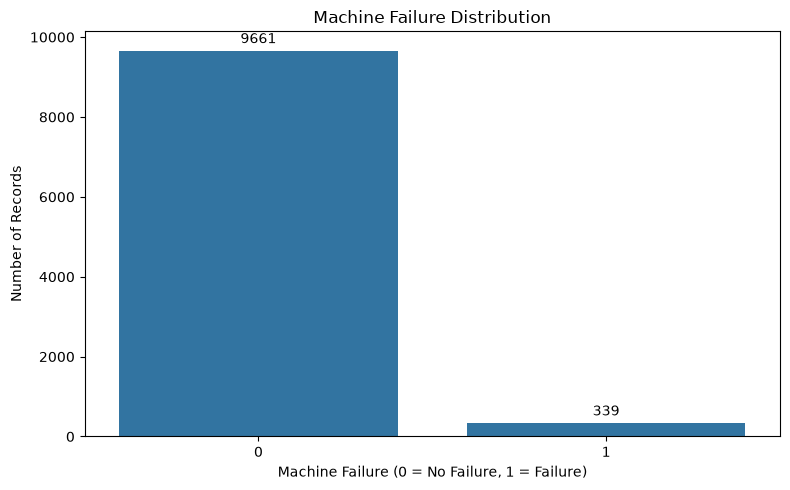

In [4]:
# Purpose: Analyze machine failure distribution and identify class imbalance.

failure_counts = df["Machine failure"].value_counts().sort_index()
failure_percentages = df["Machine failure"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": failure_percentages
})

display(target_summary)

# Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x="Machine failure")

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 4. Target Variable Distribution

The target variable `Machine failure` shows a significant class imbalance.

- **No Failure (0):** 9,661 records (96.61%).
- **Failure (1):** 339 records (3.39%).

The dataset is highly imbalanced, with failure cases representing only a small proportion of observations.

**Business implication:** A model that predicts every machine as operational could achieve 96.61% accuracy while failing to identify any actual machine failures.

Therefore, accuracy alone is not a reliable evaluation metric. We will prioritize Recall, Precision, F1-score, and PR-AUC to assess failure detection performance.

We will also investigate suitable class-imbalance handling techniques during model development.

In [5]:
# Purpose: Analyze the distribution of numerical operating parameters.

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Display descriptive statistics
display(df[numerical_features].describe())

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


## 5. Numerical Feature Analysis

The descriptive statistics provide an overview of the five machine operating parameters.

Key observations:

- **Air Temperature:** Mean of 300.00 K, with relatively low variation.
- **Process Temperature:** Mean of 310.01 K, indicating stable temperature measurements.
- **Rotational Speed:** Mean of 1538.78 rpm, with a maximum of 2886 rpm.
- **Torque:** Mean of 39.99 Nm, with values ranging from 3.8 to 76.6 Nm.
- **Tool Wear:** Mean of 107.95 minutes, ranging from 0 to 253 minutes.

The numerical features have different measurement scales and distributions. This will be considered during preprocessing, particularly when preparing data for Logistic Regression and ANN.

The maximum rotational speed and other extreme values will be investigated further rather than automatically treated as errors.

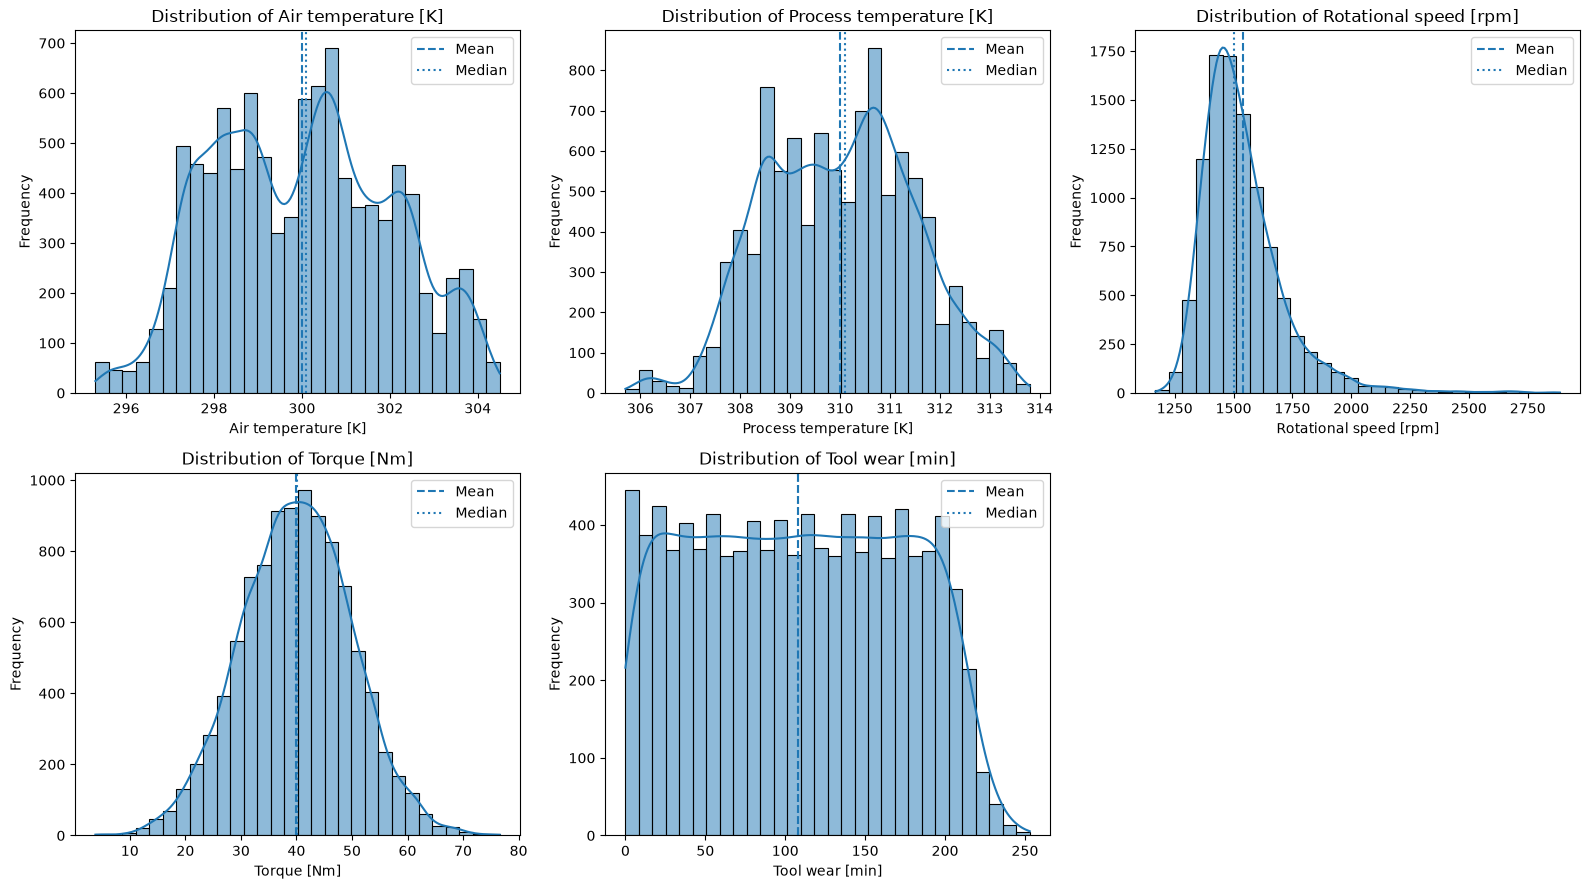

In [6]:
# Visualize numerical feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.histplot(data=df, x=column, bins=30, kde=True, ax=axes[i])

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

    # Add mean and median reference lines
    axes[i].axvline(df[column].mean(), linestyle="--", label="Mean")
    axes[i].axvline(df[column].median(), linestyle=":", label="Median")
    axes[i].legend()

# Remove unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [7]:
# Hidden missing-value detection

# Purpose: Identify hidden missing-value representations in the dataset.

missing_tokens = [
    "", " ", "NA", "N/A", "NaN", "nan", "NAN",
    "NULL", "null", "None", "none", "?"
]

hidden_missing = {}

for column in df.columns:
    if df[column].dtype == "object":

        values = df[column].astype("string").str.strip()

        count = values.isin(missing_tokens).sum()

        if count > 0:
            hidden_missing[column] = count

print("Hidden Missing Values:")

if hidden_missing:
    display(pd.Series(hidden_missing, name="Count"))
else:
    print("No hidden missing-value representations found.")

print("\nTotal Hidden Missing Values:", sum(hidden_missing.values()))

Hidden Missing Values:
No hidden missing-value representations found.

Total Hidden Missing Values: 0


## Hidden Missing-Value Detection

Standard null checks may not identify missing values represented as text, such as `NA`, `N/A`, `NaN`, `NULL`, `None`, question marks, or empty strings.

To address this, additional validation was performed on categorical columns by checking for common hidden missing-value representations.

**Findings:**
- Hidden missing values detected: 0
- No suspicious missing-value tokens were found.

**Conclusion:** No hidden missing-value representations were identified. Therefore, no additional missing-value cleaning is required at this stage.

In [8]:
import re

# Purpose: Detect hidden missing values using regex patterns.

missing_pattern = re.compile(
    r"^\s*(?:"
    r"na|n/a|nan|null|none|"
    r"missing|not available|not applicable|"
    r"undefined|unknown|"
    r"[-]+|[?]+|"
    r"0|"
    r")\s*$",
    flags=re.IGNORECASE
)

hidden_missing_results = {}

for column in df.columns:

    if df[column].dtype == "object" or pd.api.types.is_string_dtype(df[column]):

        values = df[column].astype("string")

        matches = values.str.fullmatch(missing_pattern, na=False)

        if matches.any():
            hidden_missing_results[column] = {
                "Count": int(matches.sum()),
                "Values": values[matches].unique().tolist()
            }

print("REGEX-BASED HIDDEN MISSING VALUE AUDIT")
print("-" * 50)

if hidden_missing_results:
    for column, result in hidden_missing_results.items():
        print(f"\nColumn: {column}")
        print(f"Count: {result['Count']}")
        print(f"Values: {result['Values']}")
else:
    print("No regex-based hidden missing values detected.")

print("\nTotal Hidden Missing Values:",
      sum(x["Count"] for x in hidden_missing_results.values()))

REGEX-BASED HIDDEN MISSING VALUE AUDIT
--------------------------------------------------
No regex-based hidden missing values detected.

Total Hidden Missing Values: 0


## 4. Advanced Hidden Missing-Value Detection Using Regex

To strengthen the data-quality assessment, Regular Expressions (Regex) were used to identify hidden missing-value representations that may not be detected through standard null checks.

The validation covered common representations such as:
- NA, N/A, NaN and NULL
- None and Undefined
- Missing and Unknown
- Empty strings, question marks, and placeholder dashes

**Findings:**
- Regex-based hidden missing values: 0
- No suspicious missing-value representations were detected in the categorical columns.

**Conclusion:** Both standard and regex-based checks indicate that the dataset contains no detectable missing-value representations. No missing-value treatment is required.

In [9]:
# Outlier detection using IQR

# Purpose: Quantify potential outliers using the Interquartile Range (IQR) method.

outlier_results = []

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


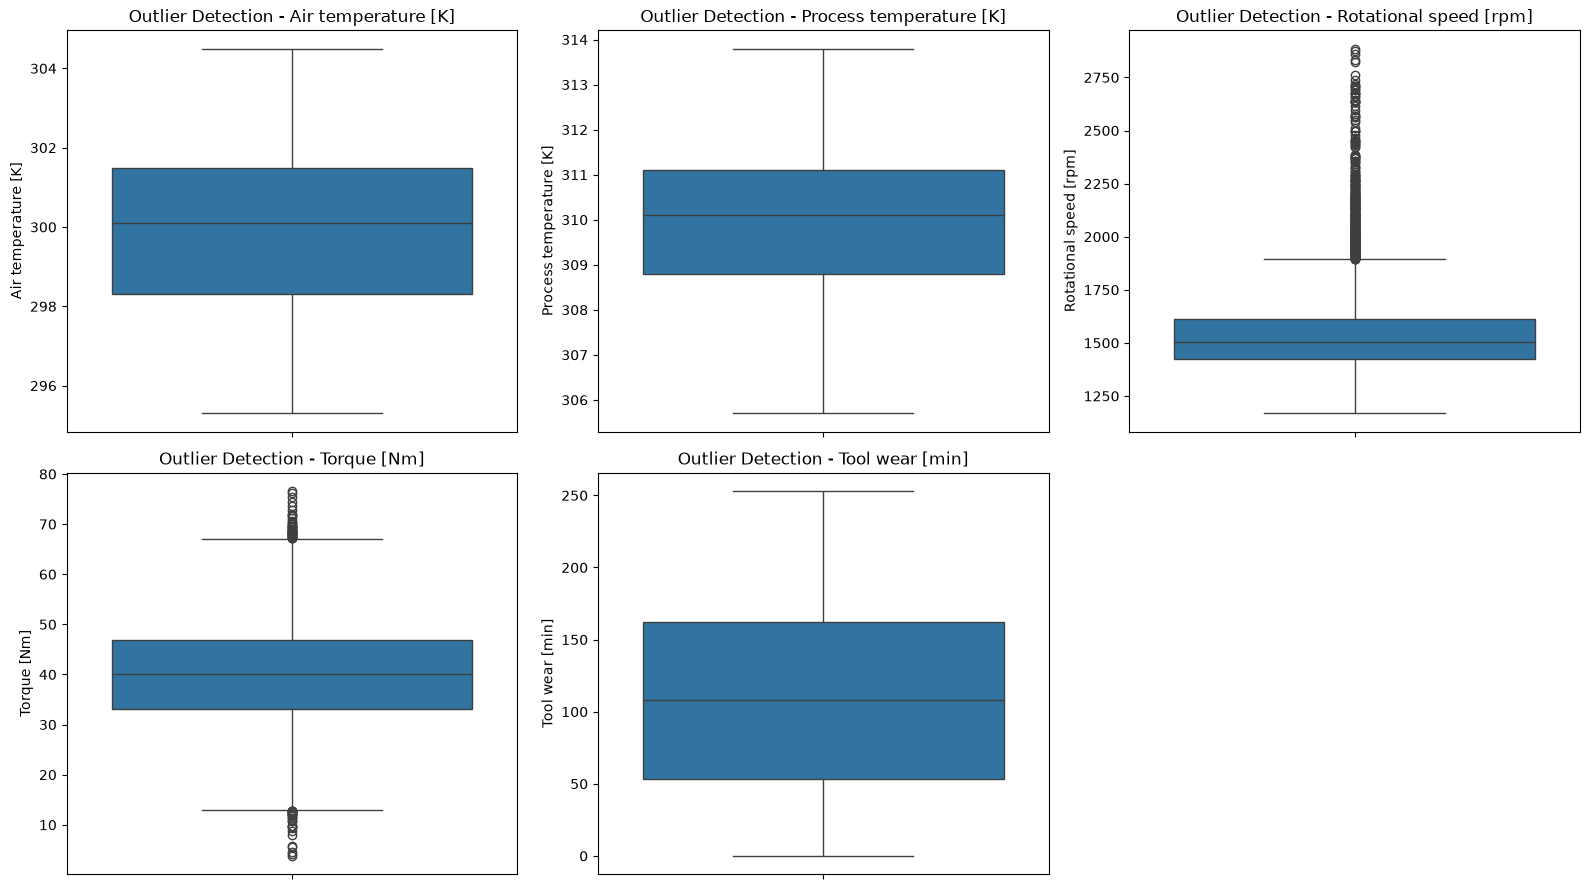

In [10]:
# Outlier detection using boxplots

# Purpose: Visualize potential outliers in numerical operating parameters.

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):

    sns.boxplot(y=df[column], ax=axes[i])

    axes[i].set_title(f"Outlier Detection - {column}")
    axes[i].set_ylabel(column)

plt.delaxes(axes[5])

plt.tight_layout()
plt.show()

## Outlier Analysis and Treatment Decision

The IQR method identified potential outliers in Rotational Speed and Torque, while Air Temperature, Process Temperature, and Tool Wear showed no outliers.

Key findings:
- Rotational Speed: 418 outliers (4.18%).
- Torque: 69 outliers (0.69%).
- Other numerical features: No detected outliers.

These extreme observations may represent genuine machine operating conditions rather than data-entry errors.

**Treatment Decision:**

We will retain the identified outliers at this stage instead of automatically removing or capping them.

Since unusual rotational speeds and torque levels may contain useful information about machine failure conditions, their relationship with the target variable will be investigated before making any treatment decisions.

In [11]:
# Outliers against machine failure

# Purpose: Examine the relationship between potential outliers and machine failures.

outlier_features = ["Rotational speed [rpm]", "Torque [Nm]"]

outlier_comparison = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    for status, mask in [
        ("Outlier", outlier_mask),
        ("Normal", ~outlier_mask)
    ]:

        total = mask.sum()
        failures = df.loc[mask, "Machine failure"].sum()

        outlier_comparison.append({
            "Feature": column,
            "Group": status,
            "Records": total,
            "Failures": failures,
            "Failure Rate (%)": round(
                failures / total * 100, 2
            ) if total > 0 else 0
        })

comparison_df = pd.DataFrame(outlier_comparison)

display(comparison_df)

,Feature,Group,Records,Failures,Failure Rate (%)
0,Rotational speed [rpm],Outlier,418,35,8.37
1,Rotational speed [rpm],Normal,9582,304,3.17
2,Torque [Nm],Outlier,69,62,89.86
3,Torque [Nm],Normal,9931,277,2.79


## Outlier Relationship with Machine Failure

To understand whether extreme operating conditions are associated with machine failures, the detected outliers were compared against normal observations.

**Key Findings:**

1. **Rotational Speed:**
   - Outlier failure rate: 8.37%.
   - Normal observation failure rate: 3.17%.
   - Outlier observations show a higher failure rate than normal observations.

2. **Torque:**
   - Outlier failure rate: 89.86%.
   - Normal observation failure rate: 2.79%.
   - Torque outliers show a significantly higher failure rate.

**Interpretation:**

Extreme rotational speeds and torque measurements may contain valuable information for identifying potential machine failures. The relationship is particularly strong for torque outliers.

**Treatment Decision:**

We will retain these observations without removing or capping them, as they may represent meaningful machine operating conditions.

These findings indicate statistical associations, not proof that extreme values directly cause machine failures.

In [12]:
# Analyze lower and upper outliers separately

# Purpose: Compare failure rates across lower, normal, and upper operating ranges.

directional_results = []

for column in outlier_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    conditions = [
        df[column] < lower_bound,
        df[column] > upper_bound
    ]

    groups = ["Lower Outlier", "Upper Outlier"]

    for condition, group in zip(conditions, groups):

        subset = df[condition]

        directional_results.append({
            "Feature": column,
            "Group": group,
            "Records": len(subset),
            "Failures": subset["Machine failure"].sum(),
            "Failure Rate (%)": round(
                subset["Machine failure"].mean() * 100, 2
            ) if len(subset) > 0 else 0
        })

    normal = df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]

    directional_results.append({
        "Feature": column,
        "Group": "Normal",
        "Records": len(normal),
        "Failures": normal["Machine failure"].sum(),
        "Failure Rate (%)": round(
            normal["Machine failure"].mean() * 100, 2
        )
    })

directional_summary = pd.DataFrame(directional_results)

display(directional_summary)

,Feature,Group,Records,Failures,Failure Rate (%)
0,Rotational speed [rpm],Lower Outlier,0,0,0.00
1,Rotational speed [rpm],Upper Outlier,418,35,8.37
2,Rotational speed [rpm],Normal,9582,304,3.17
3,Torque [Nm],Lower Outlier,28,25,89.29
4,Torque [Nm],Upper Outlier,41,37,90.24
5,Torque [Nm],Normal,9931,277,2.79


## Directional Outlier Analysis

The lower and upper outliers were analyzed separately to understand their relationship with machine failures.

**Key Findings:**

1. **Rotational Speed:**
   - No lower outliers were detected.
   - Upper outliers: 418 records, with an 8.37% failure rate.
   - Normal observations: 3.17% failure rate.

2. **Torque:**
   - Lower outliers: 28 records, with an 89.29% failure rate.
   - Upper outliers: 41 records, with a 90.24% failure rate.
   - Normal observations: 2.79% failure rate.

**Interpretation:**

Both unusually low and high torque measurements show a significantly higher association with machine failures. Upper rotational-speed outliers also show an increased failure rate.

**Final Treatment Decision:**

All identified outliers will be retained because they may represent meaningful abnormal machine operating conditions.

Removing or capping these observations could eliminate valuable failure-related information and negatively affect model performance.

,Type,Records,Failures,Failure_Rate
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


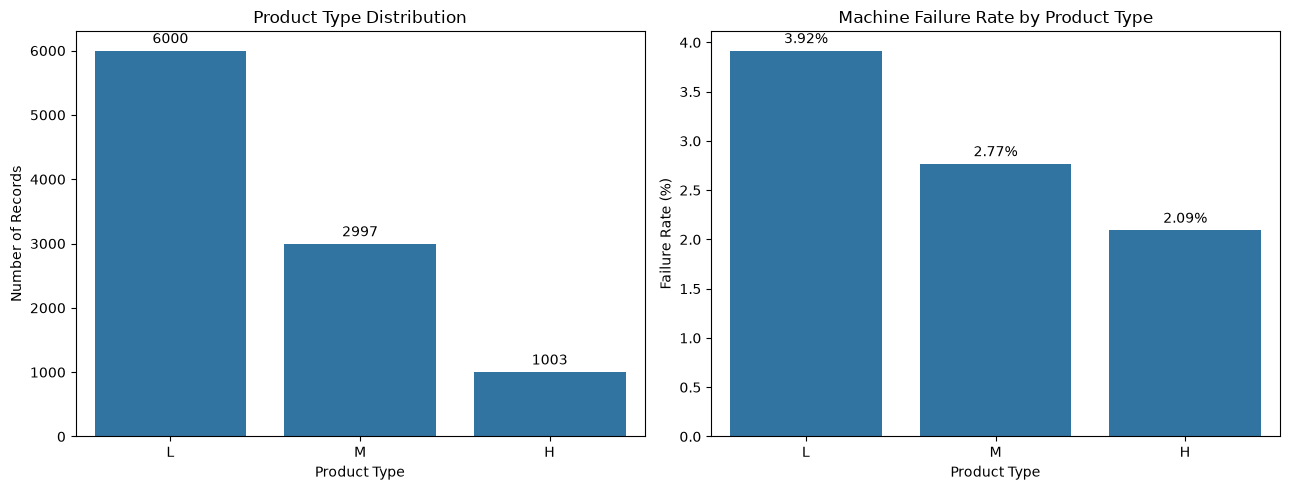

In [13]:
# Categorical feature analysis

# Purpose: Analyze product type distribution and machine failure rates.

type_summary = df.groupby("Type").agg(
    Records=("Machine failure", "count"),
    Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
).reset_index()

type_summary["Failure_Rate"] *= 100

display(type_summary.round(2))

# Visualize product type distribution and failure rates
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Product type counts
ax1 = sns.countplot(data=df, x="Type", order=["L", "M", "H"], ax=axes[0])

for container in ax1.containers:
    ax1.bar_label(container, fmt="%.0f", padding=3)

ax1.set_title("Product Type Distribution")
ax1.set_xlabel("Product Type")
ax1.set_ylabel("Number of Records")

# Failure rate by product type
ax2 = sns.barplot(
    data=type_summary,
    x="Type",
    y="Failure_Rate",
    order=["L", "M", "H"],
    ax=axes[1]
)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.2f%%", padding=3)

ax2.set_title("Machine Failure Rate by Product Type")
ax2.set_xlabel("Product Type")
ax2.set_ylabel("Failure Rate (%)")

plt.tight_layout()
plt.show()

## Categorical Feature Analysis

The product quality category (`Type`) was analyzed to understand its distribution and relationship with machine failures.

The dataset contains three categories:
- L – Low Quality
- M – Medium Quality
- H – High Quality

**Key Findings:**

- **Type L:** 6,000 records, 235 failures, 3.92% failure rate.
- **Type M:** 2,997 records, 83 failures, 2.77% failure rate.
- **Type H:** 1,003 records, 21 failures, 2.09% failure rate.

**Interpretation:**

Type L has the highest observed failure rate, whereas Type H has the lowest.

These findings indicate an association between product category and machine failure, but do not establish a causal relationship.

The `Type` feature will be retained for model development and appropriately encoded during preprocessing.

,No Failure,Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


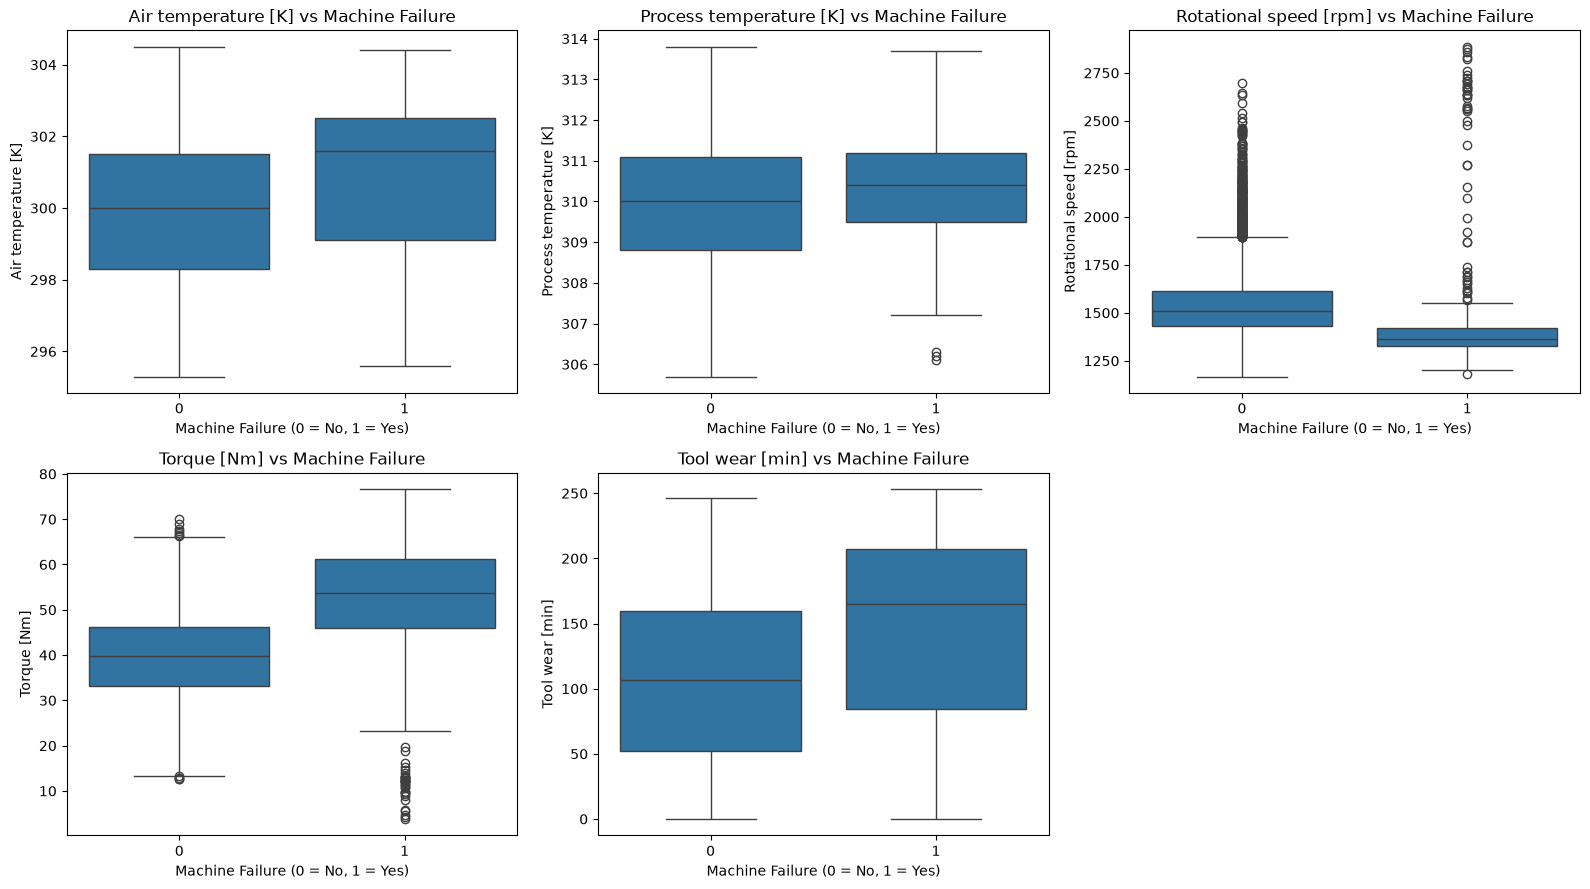

In [14]:
# Operating parameters vs machine failure

# Purpose: Compare operating parameters across machine failure classes.

failure_comparison = df.groupby("Machine failure")[numerical_features].mean().T

failure_comparison.columns = ["No Failure", "Failure"]

display(failure_comparison.round(2))

# Visualize operating parameters against machine failure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(numerical_features):

    ax = sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        ax=axes[i]
    )

    ax.set_title(f"{column} vs Machine Failure")
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_ylabel(column)

plt.delaxes(axes[5])

plt.tight_layout()
plt.show()

## Operating Parameters vs Machine Failure

The numerical operating parameters were compared across machines with and without failures using descriptive statistics and boxplots.

**Key Findings:**

- **Air Temperature:** Slightly higher average temperature in failed machines (300.89 K).
- **Process Temperature:** Only a small difference between the two groups.
- **Rotational Speed:** Failed machines show a lower average speed (1496.49 rpm).
- **Torque:** Failed machines show higher average torque (50.17 Nm).
- **Tool Wear:** Failed machines have higher average tool wear (143.78 minutes).

**Interpretation:**

Torque and Tool Wear show noticeable increases in failed machines, while Rotational Speed shows a decrease. Temperature measurements show comparatively smaller differences.

**Conclusion:**

Torque, Tool Wear, and Rotational Speed appear to be important operating parameters for further investigation in machine failure prediction.

These observations indicate associations, not direct causation. All five numerical features will be retained for model development.

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.00,0.88,0.02,-0.01,0.01,0.08
Process temperature [K],0.88,1.00,0.02,-0.01,0.01,0.04
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00,-0.04
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00,0.19
Tool wear [min],0.01,0.01,0.00,-0.00,1.00,0.11
Machine failure,0.08,0.04,-0.04,0.19,0.11,1.00


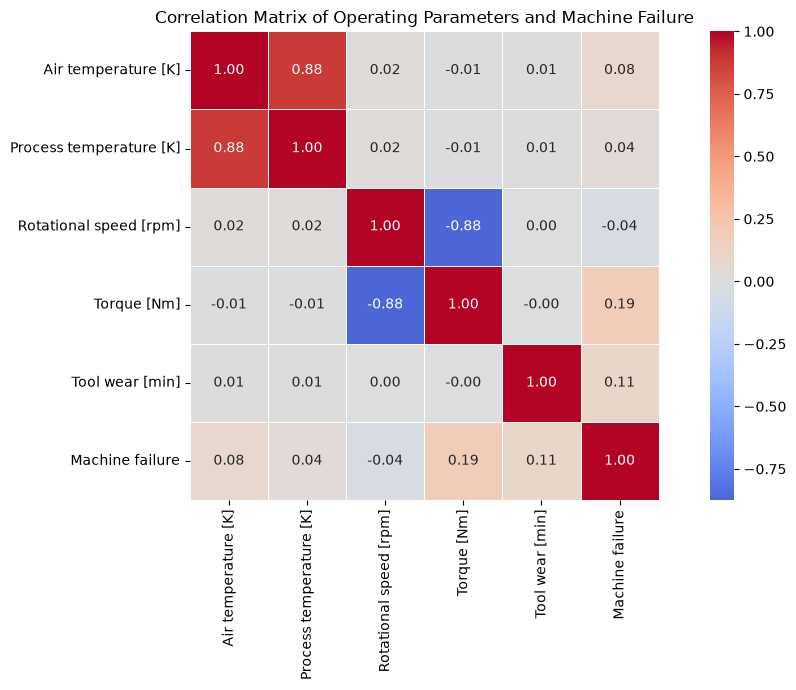

In [15]:
# Correlation Analysis

# Purpose: Analyze correlations between numerical features and machine failure.

correlation_features = numerical_features + ["Machine failure"]

correlation_matrix = df[correlation_features].corr(method="pearson")

# Display correlation values
display(correlation_matrix.round(2))

# Visualize the correlation matrix
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Operating Parameters and Machine Failure")
plt.tight_layout()
plt.show()

## Correlation Analysis

Pearson correlation was used to examine linear relationships between numerical operating parameters and machine failure.

**Key Findings:**

- Torque has the highest positive correlation with machine failure (0.19).
- Tool Wear shows a positive correlation of 0.11.
- Air Temperature and Process Temperature show weak positive correlations.
- Rotational Speed has a weak negative correlation (-0.04).

**Feature Relationships:**

- Air Temperature and Process Temperature show a strong positive correlation (0.88).
- Rotational Speed and Torque show a strong negative correlation (-0.88).

**Interpretation:**

Although individual features show relatively weak linear correlations with machine failure, they may still contribute to prediction through nonlinear relationships and feature interactions.

The strong correlations between certain input features will also be considered during model development, particularly when evaluating multicollinearity.

**Conclusion:**

All five numerical operating parameters will be retained for further analysis. Feature importance and predictive contribution will be evaluated using the developed models rather than relying solely on correlation values.

In [16]:
# Feature selection and data leakage audit

# Purpose: Identify valid input features and prevent data leakage.

# Identifier columns
identifier_columns = ["UDI", "Product ID"]

# Target variable
target_column = "Machine failure"

# Failure-mode columns that must be excluded
leakage_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Valid input features
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Verify that all expected columns exist
expected_columns = (
    identifier_columns + feature_columns +
    [target_column] + leakage_columns
)

assert set(expected_columns) == set(df.columns), "Unexpected dataset columns detected."

# Create feature and target datasets
X = df[feature_columns].copy()
y = df[target_column].copy()

# Display feature selection summary
feature_audit = pd.DataFrame({
    "Column": expected_columns,
    "Role": (
        ["Identifier"] * len(identifier_columns) +
        ["Input Feature"] * len(feature_columns) +
        ["Target"] +
        ["Excluded - Data Leakage"] * len(leakage_columns)
    )
})

display(feature_audit)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Leakage Columns Included:",
      any(column in X.columns for column in leakage_columns))

,Column,Role
0,UDI,Identifier
1,Product ID,Identifier
2,Type,Input Feature
3,Air temperature [K],Input Feature
4,Process temperature [K],Input Feature
5,Rotational speed [rpm],Input Feature
6,Torque [Nm],Input Feature
7,Tool wear [min],Input Feature
8,Machine failure,Target
9,TWF,Excluded - Data Leakage


Input Features Shape: (10000, 6)
Target Shape: (10000,)
Leakage Columns Included: False


## Feature Selection and Validation

The feature selection audit confirms that six valid input features and one target variable have been selected.

Identifier columns (`UDI`, `Product ID`) and five failure-mode indicators (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) have been excluded.

The leakage validation confirms that none of the excluded failure-mode columns are present in the input features.

**Conclusion:** The selected dataset is ready for train-test splitting and subsequent preprocessing.

In [17]:
# Train-Test Split

# Purpose: Split the dataset while preserving machine failure class proportions.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Compare class distributions
split_summary = pd.DataFrame({
    "Training Count": y_train.value_counts().sort_index(),
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Testing Count": y_test.value_counts().sort_index(),
    "Testing (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

display(split_summary.round(2))

Training Features: (8000, 6)
Testing Features: (2000, 6)

Training Target: (8000,)
Testing Target: (2000,)


,Training Count,Training (%),Testing Count,Testing (%)
Machine failure,,,,
0,7729,96.61,1932,96.6
1,271,3.39,68,3.4


## Train-Test Split

The dataset was divided into training (80%) and testing (20%) sets using stratified sampling.

Stratification was applied to preserve the original machine failure distribution across both datasets.

**Results:**
- Training records: 8,000
- Testing records: 2,000
- Training failure cases: 271
- Testing failure cases: 68

**Conclusion:**

The class distribution is consistently maintained across both sets. The test dataset will remain untouched during model training, preprocessing decisions, and hyperparameter tuning to ensure an unbiased final evaluation.

In [18]:
# Create a validation set

# Purpose: Create a validation set for model selection and tuning.

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Verify dataset dimensions
print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)
print("Testing Features:", X_test.shape)

# Compare class distributions
validation_summary = pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Testing": y_test.value_counts().sort_index()
})

display(validation_summary)

Training Features: (6400, 6)
Validation Features: (1600, 6)
Testing Features: (2000, 6)


,Training,Validation,Testing
Machine failure,,,
0,6183,1546,1932
1,217,54,68


## Training, Validation and Testing Split

The original dataset was divided into three subsets using stratified sampling:

- Training: 64% (6,400 records)
- Validation: 16% (1,600 records)
- Testing: 20% (2,000 records)

**Purpose of Each Dataset:**

- Training data: Model fitting and learning.
- Validation data: Model selection, hyperparameter tuning and threshold evaluation.
- Testing data: Final unbiased model evaluation.

The failure-class distribution is maintained across all three subsets.

**Conclusion:** The data is ready for preprocessing and model development. The test dataset will remain untouched until final evaluation.

In [19]:
# Feature preprocessing

# Purpose: Scale numerical features and encode categorical features.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical columns
numerical_columns = numerical_features
categorical_columns = ["Type"]

# Define preprocessing transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and testing data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
processed_feature_names = preprocessor.get_feature_names_out()

# Display transformed datasets
print("Training Shape:", X_train_processed.shape)
print("Validation Shape:", X_val_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nTransformed Features:")
print(processed_feature_names)

Training Shape: (6400, 8)
Validation Shape: (1600, 8)
Testing Shape: (2000, 8)

Transformed Features:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


## Feature Preprocessing

Applied StandardScaler to the five numerical features and One-Hot Encoding to the categorical feature `Type`.

The categorical feature was converted into three binary columns: `Type_H`, `Type_L`, and `Type_M`.

The preprocessing pipeline was fitted exclusively on the training dataset and applied to the validation and testing datasets to prevent data leakage.

Final feature dimensions:
- Training: 6,400 × 8
- Validation: 1,600 × 8
- Testing: 2,000 × 8

The final dataset contains eight model-ready features, with all identified outliers retained to preserve potentially meaningful failure-related information.

## Outlier Treatment Decision

The IQR method identified potential outliers in Rotational Speed and Torque.

Further investigation revealed higher machine failure rates among these observations, particularly for lower and upper Torque outliers.

Since these extreme values may represent meaningful machine operating conditions rather than data errors, they will be retained without removal or capping.

StandardScaler will be applied to numerical features during preprocessing. However, scaling does not eliminate the influence of extreme observations.

**Conclusion:** All identified outliers are retained to preserve potentially valuable failure-related information. Their influence will be considered during model evaluation.

# Phase 2 — ML and ANN Development

## Phase 2.1 — Logistic Regression Baseline 


### 2.1 Logistic Regression — Baseline Model

Logistic Regression is selected as the initial baseline classification algorithm for predicting machine failures.

It estimates the probability of machine failure using the available operating parameters and classifies observations into failure and non-failure categories.

**Implementation approach:**

- Use the preprocessed training dataset.
- Apply `class_weight="balanced"` to address class imbalance.
- Train the model using Logistic Regression.
- Generate predictions and failure probabilities on the validation dataset.
- Evaluate performance using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

**Objective:** Establish a baseline performance benchmark against which ensemble models, ANN and subsequent optimization experiments can be compared.

The test dataset will not be used during this experiment.


In [20]:

# Purpose: Train a class-weighted Logistic Regression baseline model.

from sklearn.linear_model import LogisticRegression

# Initialize the model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

# Train using the preprocessed training dataset
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [21]:

# Purpose: Generate predicted classes and failure probabilities
# using the validation dataset.

# Predict machine failure classes
y_lr_val_pred = lr_model.predict(X_val_processed)

# Predict probability of machine failure
y_lr_val_prob = lr_model.predict_proba(X_val_processed)[:, 1]

print("Validation predictions generated successfully.")
print("Predicted classes:", y_lr_val_pred.shape)
print("Predicted probabilities:", y_lr_val_prob.shape)


Validation predictions generated successfully.
Predicted classes: (1600,)
Predicted probabilities: (1600,)


In [22]:

# Purpose: Evaluate Logistic Regression using classification metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Calculate evaluation metrics
lr_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_lr_val_pred),
    "Precision": precision_score(y_val, y_lr_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_lr_val_pred, zero_division=0),
    "F1-Score": f1_score(y_val, y_lr_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_lr_val_prob),
    "PR-AUC": average_precision_score(y_val, y_lr_val_prob)
}

# Display evaluation results
lr_results = pd.DataFrame([lr_metrics])

display(lr_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197


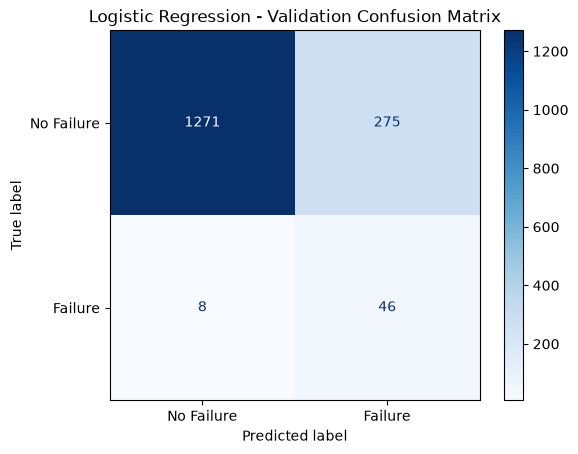

Classification Report:

              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1546
     Failure       0.14      0.85      0.25        54

    accuracy                           0.82      1600
   macro avg       0.57      0.84      0.57      1600
weighted avg       0.97      0.82      0.88      1600



In [23]:

# Purpose: Analyze correct and incorrect failure predictions.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Generate confusion matrix
lr_cm = confusion_matrix(y_val, y_lr_val_pred)

# Display confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

# Display classification report
print("Classification Report:\n")
print(
    classification_report(
        y_val,
        y_lr_val_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)



### Logistic Regression — Baseline Evaluation

The Logistic Regression model achieved the following validation results:

- Accuracy: 82.31%
- Precision: 14.33%
- Recall: 85.19%
- F1-Score: 24.53%
- ROC-AUC: 89.27%
- PR-AUC: 41.97%

**Key Observations:**

- The model successfully detected 46 out of 54 actual machine failures.
- Recall of 85.19% indicates that the model identifies most failure cases.
- However, precision of 14.33% indicates a high number of false alarms.
- The model generated 275 false positives and missed 8 actual failures.

**Conclusion:**

Logistic Regression demonstrates promising failure detection capability due to its high recall. However, its low precision indicates that many normal machines are incorrectly classified as failures, potentially increasing unnecessary inspection costs.

Therefore, Logistic Regression establishes our initial baseline, but its prediction quality requires further improvement. We will compare it with ensemble models and ANN before selecting the most suitable approach.

-----------------------------------------------------------------------------

### 2.2 Random Forest — Baseline Model

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions. Each tree is trained using a different bootstrap sample, and their predictions are aggregated to produce the final classification.

**Why Random Forest?**

- Captures complex, non-linear relationships between machine operating parameters.
- Handles interactions between multiple sensor measurements.
- Reduces the risk of overfitting compared with relying on a single decision tree.
- Provides feature importance estimates for understanding influential operating parameters.

**Implementation approach:**

- Use the same preprocessed training and validation datasets.
- Apply `class_weight="balanced"` to address class imbalance.
- Train an initial Random Forest classifier without hyperparameter tuning.
- Generate validation predictions and failure probabilities.
- Evaluate using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

**Objective:** Establish an ensemble-model baseline and compare its failure detection capability against Logistic Regression.


### Train the Random Forest model

In [24]:

# Purpose: Train a class-weighted Random Forest baseline model.

from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using the preprocessed training dataset
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.


### Generate validation predictions

In [25]:

# Purpose: Generate predicted classes and failure probabilities
# using the validation dataset.

# Predict machine failure classes
y_rf_val_pred = rf_model.predict(X_val_processed)

# Predict probability of machine failure
y_rf_val_prob = rf_model.predict_proba(X_val_processed)[:, 1]

print("Validation predictions generated successfully.")
print("Predicted classes:", y_rf_val_pred.shape)
print("Predicted probabilities:", y_rf_val_prob.shape)


Validation predictions generated successfully.
Predicted classes: (1600,)
Predicted probabilities: (1600,)


### Evaluate model performance

In [26]:

# Purpose: Evaluate Random Forest using classification metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Calculate evaluation metrics
rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_val, y_rf_val_pred),
    "Precision": precision_score(y_val, y_rf_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_rf_val_pred, zero_division=0),
    "F1-Score": f1_score(y_val, y_rf_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_rf_val_prob),
    "PR-AUC": average_precision_score(y_val, y_rf_val_prob)
}

# Display evaluation results
rf_results = pd.DataFrame([rf_metrics])

display(rf_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.975,0.6346,0.6111,0.6226,0.9524,0.6866


### Confusion matrix and classification report

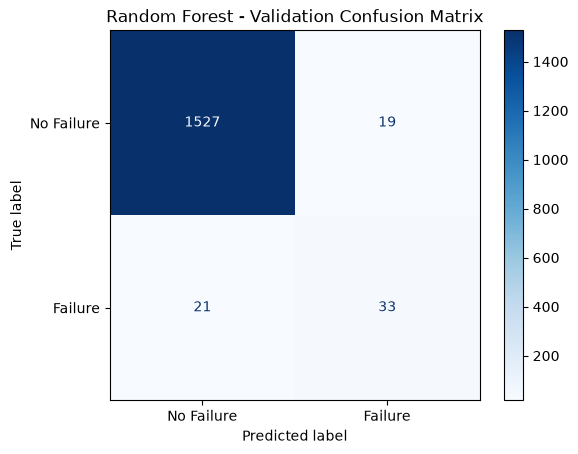

Classification Report:

              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1546
     Failure       0.63      0.61      0.62        54

    accuracy                           0.97      1600
   macro avg       0.81      0.80      0.80      1600
weighted avg       0.97      0.97      0.97      1600



In [27]:

# Purpose: Analyze correct and incorrect Random Forest predictions.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Generate confusion matrix
rf_cm = confusion_matrix(y_val, y_rf_val_pred)

# Display confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Validation Confusion Matrix")
plt.show()

# Display classification report
print("Classification Report:\n")
print(
    classification_report(
        y_val,
        y_rf_val_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)



### Random Forest — Baseline Evaluation

The Random Forest model achieved the following validation results:

- Accuracy: 97.50%
- Precision: 63.46%
- Recall: 61.11%
- F1-Score: 62.26%
- ROC-AUC: 95.24%
- PR-AUC: 68.66%

**Key Observations:**

- The model correctly identified 33 out of 54 actual machine failures.
- Precision of 63.46% indicates a considerably lower false-alarm rate than Logistic Regression.
- The model generated 19 false positives and missed 21 actual failures.
- Its F1-score and PR-AUC indicate a better overall precision-recall balance than the Logistic Regression baseline.

**Conclusion:**

Random Forest demonstrates stronger overall baseline performance than Logistic Regression, particularly in precision, F1-score and PR-AUC. However, its recall of 61.11% indicates that it misses a considerable number of actual machine failures.

Further improvements are required to increase failure detection while maintaining an acceptable number of false alarms. We will investigate class imbalance handling and hyperparameter optimization in subsequent experiments.

-----------------------------------------------------------------------------


### 2.3 Artificial Neural Network (ANN) — Baseline Model

An Artificial Neural Network (ANN) is a deep learning model inspired by the interconnected structure of biological neurons. It learns patterns by passing input features through multiple layers of neurons and adjusting weights during training.

**Why ANN?**

- Learns complex, non-linear relationships between machine operating parameters.
- Captures interactions among multiple sensor measurements.
- Can learn patterns that simpler linear models may not capture.
- Provides an opportunity to compare deep learning performance against traditional ML algorithms.

**Implementation approach:**

- Use the same preprocessed training and validation datasets.
- Calculate class weights to address the imbalanced target variable.
- Build a feedforward neural network using TensorFlow/Keras.
- Train using the Adam optimizer and Binary Crossentropy loss.
- Apply Early Stopping to reduce unnecessary training and monitor validation loss.
- Evaluate using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

**Objective:** Establish an ANN baseline and investigate whether a neural network can provide better machine failure detection than traditional ML models.


### Calculate class weights

In [28]:

# Purpose: Calculate class weights to address the imbalance
# between normal machine operations and machine failures.

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Identify the unique target classes
classes = np.unique(y_train)

# Calculate balanced class weights using training labels only
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Convert weights into a dictionary for Keras
ann_class_weights = dict(zip(classes, class_weights))

print("ANN Class Weights:")
print(ann_class_weights)


ANN Class Weights:
{np.int64(0): np.float64(0.5175481158013909), np.int64(1): np.float64(14.746543778801843)}


### Build and compile the ANN

In [29]:

# Purpose: Build and compile the baseline ANN architecture.

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Set random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# Initialize the ANN architecture
ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(64, activation="relu"),
    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

# Compile the ANN
ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
ann_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

### Train the ANN

In [30]:

# Purpose: Train the ANN using class weights and early stopping.

from tensorflow.keras.callbacks import EarlyStopping

# Configure Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train the ANN
ann_history = ann_model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    class_weight=ann_class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("ANN training completed.")


Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7777 - loss: 0.5359 - val_accuracy: 0.8381 - val_loss: 0.4330
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8259 - loss: 0.3827 - val_accuracy: 0.8700 - val_loss: 0.3333
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8439 - loss: 0.3444 - val_accuracy: 0.8825 - val_loss: 0.3030
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8525 - loss: 0.3235 - val_accuracy: 0.8894 - val_loss: 0.2866
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8591 - loss: 0.3073 - val_accuracy: 0.8925 - val_loss: 0.2682
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8678 - loss: 0.2919 - val_accuracy: 0.9006 - val_loss: 0.2513
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8763 - loss: 0.2770 - val_accuracy: 0.9069 - val_loss: 0.2393
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8809 - loss: 0.2638 - val_accuracy: 0.

### Visualize training performance

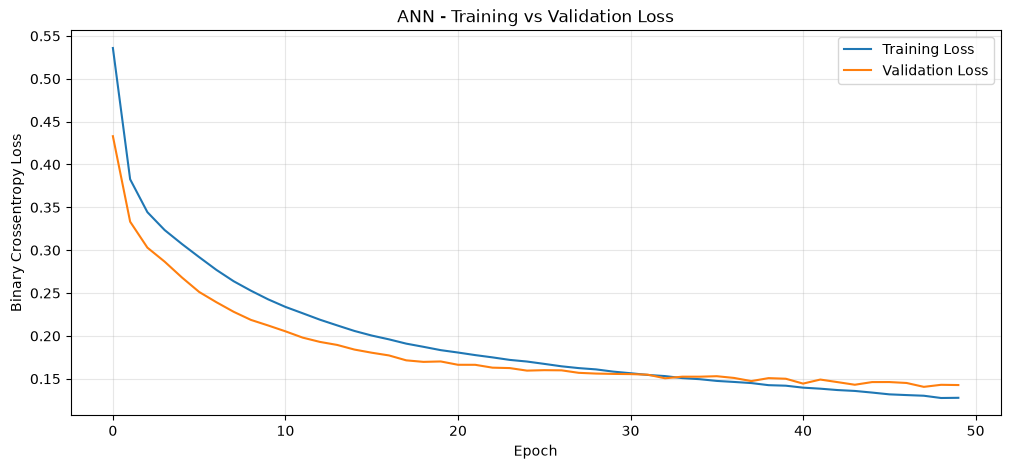

In [31]:

# Purpose: Visualize ANN training and validation loss
# to examine learning behaviour and potential overfitting.

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot training and validation loss
plt.plot(ann_history.history["loss"], label="Training Loss")
plt.plot(ann_history.history["val_loss"], label="Validation Loss")

plt.title("ANN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### Generate validation predictions

In [32]:

# Purpose: Generate ANN failure probabilities and predicted classes.

# Predict failure probabilities
y_ann_val_prob = ann_model.predict(
    X_val_processed,
    verbose=0
).flatten()

# Convert probabilities into binary predictions using threshold 0.50
y_ann_val_pred = (y_ann_val_prob >= 0.50).astype(int)

print("ANN validation predictions generated successfully.")
print("Predicted classes:", y_ann_val_pred.shape)
print("Predicted probabilities:", y_ann_val_prob.shape)


ANN validation predictions generated successfully.
Predicted classes: (1600,)
Predicted probabilities: (1600,)


### Evaluate ANN performance

In [33]:

# Purpose: Evaluate ANN using the same metrics as traditional ML models.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Calculate evaluation metrics
ann_metrics = {
    "Model": "ANN",
    "Accuracy": accuracy_score(y_val, y_ann_val_pred),
    "Precision": precision_score(y_val, y_ann_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_ann_val_pred, zero_division=0),
    "F1-Score": f1_score(y_val, y_ann_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_ann_val_prob),
    "PR-AUC": average_precision_score(y_val, y_ann_val_prob)
}

# Display evaluation results
ann_results = pd.DataFrame([ann_metrics])

display(ann_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328


### Confusion matrix and classification report

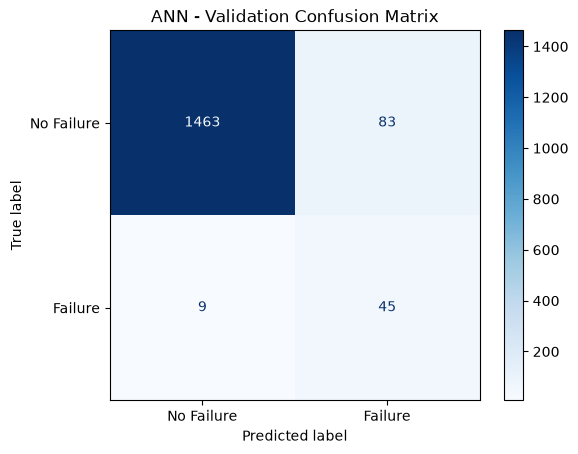

Classification Report:

              precision    recall  f1-score   support

  No Failure       0.99      0.95      0.97      1546
     Failure       0.35      0.83      0.49        54

    accuracy                           0.94      1600
   macro avg       0.67      0.89      0.73      1600
weighted avg       0.97      0.94      0.95      1600



In [34]:

# Purpose: Analyze correct and incorrect ANN predictions.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Generate confusion matrix
ann_cm = confusion_matrix(y_val, y_ann_val_pred)

# Display confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=ann_cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues", values_format="d")

plt.title("ANN - Validation Confusion Matrix")
plt.show()

# Display classification report
print("Classification Report:\n")
print(
    classification_report(
        y_val,
        y_ann_val_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)



### Artificial Neural Network (ANN) — Baseline Evaluation

The ANN model achieved the following validation results:

- Accuracy: 94.25%
- Precision: 35.16%
- Recall: 83.33%
- F1-Score: 49.45%
- ROC-AUC: 95.61%
- PR-AUC: 73.28%

**Key Observations:**

- The model correctly identified 45 out of 54 actual machine failures.
- Recall of 83.33% demonstrates strong failure detection capability.
- Precision of 35.16% indicates that false alarms remain relatively high.
- The model generated 83 false positives and missed 9 actual failures.
- The training and validation loss curves show consistent convergence without strong evidence of severe overfitting.

**Conclusion:**

The ANN demonstrates promising performance in identifying machine failures, achieving the highest PR-AUC among the three baseline models. Its high recall makes it particularly interesting for predictive maintenance, where missing actual failures can have significant operational consequences.

However, its precision and F1-score remain lower than Random Forest. Further experiments involving hyperparameter optimization and ANN configuration changes will help determine whether its performance can be improved.

The ANN baseline will be retained for subsequent controlled experiments and comparison.

----------------------------------------------------------------------------------




## 2.4 Baseline Model Performance Comparison

After developing Logistic Regression, Random Forest and Artificial Neural Network models, their validation performance is consolidated to understand their relative strengths and limitations.

All three models were evaluated using the same training and validation datasets, with consistent evaluation metrics.

**Comparison criteria:**

- Accuracy: Overall proportion of correct predictions.
- Precision: Reliability of predicted machine failures.
- Recall: Ability to identify actual machine failures.
- F1-Score: Balance between Precision and Recall.
- ROC-AUC: Ability to distinguish between failure and non-failure cases.
- PR-AUC: Performance in identifying the minority failure class.

**Objective:** Identify the strengths and limitations of each baseline model and establish benchmarks for subsequent performance improvement experiments.


### Consolidate baseline evaluation results

In [35]:

# Purpose: Consolidate evaluation metrics from all three baseline models.

# Combine individual model evaluation results
baseline_results = pd.DataFrame([
    lr_metrics,
    rf_metrics,
    ann_metrics
])

# Display consolidated comparison
display(
    baseline_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197
1,Random Forest,0.9750,0.6346,0.6111,0.6226,0.9524,0.6866
2,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328


### Identify the best-performing model for each metric

In [36]:

# Purpose: Identify which baseline model achieved the highest score
# for each evaluation metric.

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

# Find the model with the highest score for each metric
best_models = baseline_results.set_index("Model")[comparison_metrics].idxmax()

# Display the best-performing model for each metric
print("Best Baseline Model for Each Metric:\n")
display(best_models.to_frame(name="Best Performing Model"))


Best Baseline Model for Each Metric:



,Best Performing Model
Accuracy,Random Forest
Precision,Random Forest
Recall,Logistic Regression
F1-Score,Random Forest
ROC-AUC,ANN
PR-AUC,ANN


### Visual comparison of classification metrics

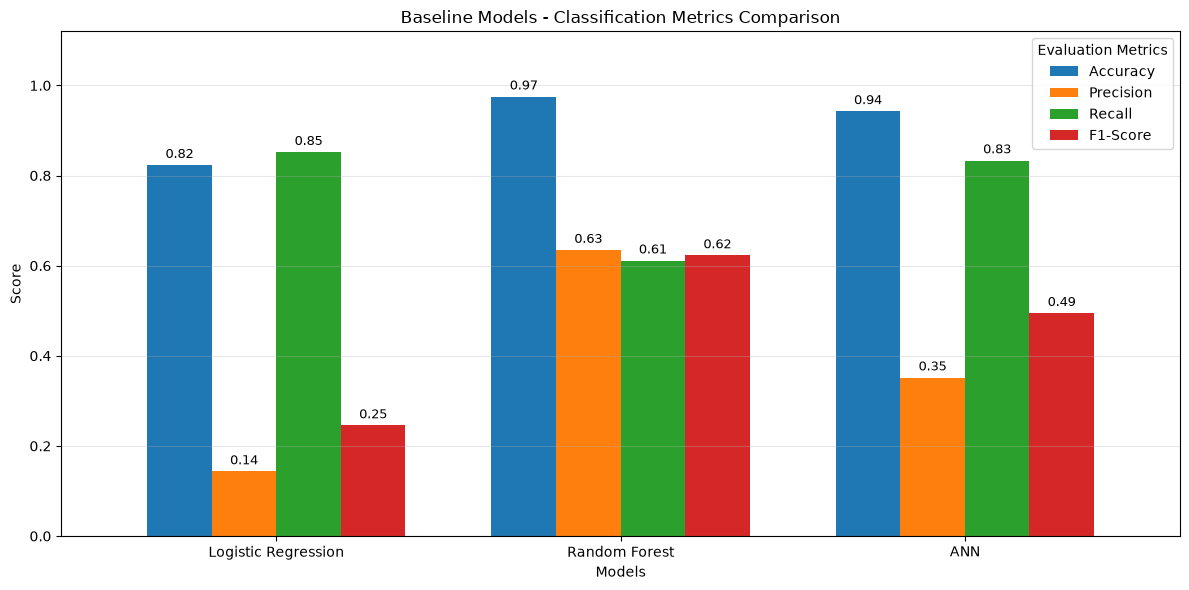

In [37]:

# Purpose: Compare classification metrics and display values on each bar.

import matplotlib.pyplot as plt

classification_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

# Prepare comparison data
plot_data = baseline_results.set_index("Model")[classification_metrics]

# Create grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

# Add values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

plt.title("Baseline Models - Classification Metrics Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### ROC-AUC and PR-AUC comparison

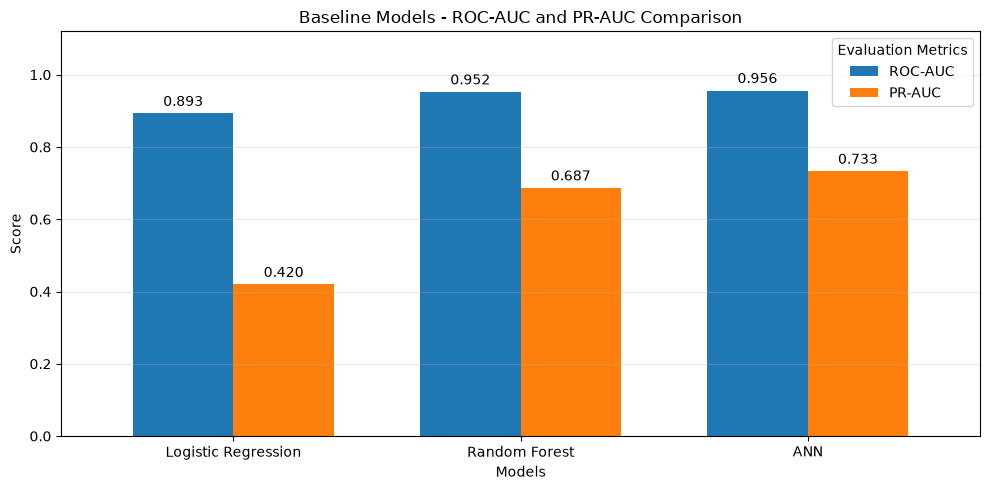

In [38]:

# Purpose: Compare ROC-AUC and PR-AUC with values displayed on bars.

ranking_metrics = ["ROC-AUC", "PR-AUC"]

# Prepare comparison data
ranking_data = baseline_results.set_index("Model")[ranking_metrics]

# Create grouped bar chart
ax = ranking_data.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

# Add values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=10
    )

plt.title("Baseline Models - ROC-AUC and PR-AUC Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### Baseline Model Comparison — Findings and Observations

The validation results reveal different performance characteristics across the three baseline models.

**1. Logistic Regression**

- Achieved the highest Recall of 85.19%.
- Detected most actual machine failures.
- Generated 275 false positives, resulting in very low Precision.
- Demonstrates a strong preference for identifying potential failures at the cost of additional false alarms.

**2. Random Forest**

- Achieved the highest Accuracy (97.50%), Precision (63.46%) and F1-Score (62.26%).
- Generated only 19 false positives.
- However, it missed 21 actual machine failures.
- Demonstrates a better balance between Precision and Recall than Logistic Regression.

**3. Artificial Neural Network**

- Achieved the highest ROC-AUC (95.61%) and PR-AUC (73.28%).
- Detected 45 out of 54 actual machine failures.
- Generated 83 false positives and missed 9 failures.
- Demonstrates promising minority-class detection and probability-ranking performance.

**Overall Conclusion:**

No single baseline model performs best across all evaluation metrics.

Random Forest provides the strongest baseline F1-Score and Precision, while ANN demonstrates the highest PR-AUC and ROC-AUC. Logistic Regression achieves the highest Recall but produces excessive false alarms.

Since missing machine failures can have significant operational consequences, improving Recall while maintaining acceptable Precision will be an important objective for subsequent experiments.

These baseline results will serve as reference benchmarks for evaluating the impact of class imbalance handling and model optimization techniques.

------------------------------------------------------------------------------------------------------------

### 2.5 — Class Imbalance Handling Experiments.


#### 2.5.1 Understanding Class Imbalance

The AI4I 2020 dataset contains significantly fewer machine-failure observations than normal operating observations.

Our training dataset contains 6,400 records, of which only 217 represent machine failures. This imbalance can influence model learning and cause classifiers to favor the majority class.

Before applying resampling techniques, we will examine the original training distribution and use it as the reference for subsequent experiments.

**Objective:** Understand the class imbalance and establish the original training distribution as a comparison benchmark.


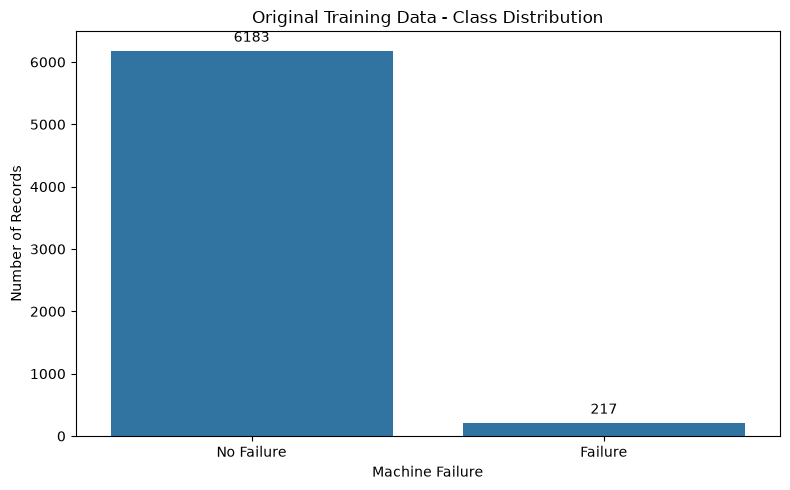

,Count,Percentage
Machine failure,,
0,6183,96.61
1,217,3.39


In [39]:

# Purpose: Visualize the original class distribution in the training dataset.

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate class counts
class_counts = y_train.value_counts().sort_index()

# Create readable class labels
class_labels = ["No Failure", "Failure"]

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_labels,
    y=class_counts.values
)

# Display count values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4)

plt.title("Original Training Data - Class Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Display class percentages
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": y_train.value_counts(normalize=True).sort_index() * 100
})

display(class_distribution.round(2))



#### 2.5.2 Random Oversampling

Random Oversampling addresses class imbalance by randomly duplicating observations from the minority class until the desired class distribution is achieved.

Unlike SMOTE, this method does not generate new synthetic observations. It increases the representation of existing failure cases in the training dataset.

**Implementation approach:**

- Apply Random Oversampling only to the training dataset.
- Balance the minority and majority classes.
- Train separate models using the resampled data.
- Evaluate using the original, unchanged validation dataset.

**Objective:** Determine whether increasing the number of existing failure observations improves the model's ability to detect machine failures.

To isolate the effect of oversampling, the resampled models will not use `class_weight="balanced"`.


In [40]:

# Purpose: Balance the training dataset using Random Oversampling.

from imblearn.over_sampling import RandomOverSampler

# Initialize Random Oversampler
random_oversampler = RandomOverSampler(
    sampling_strategy="auto",
    random_state=42
)

# Resample only the preprocessed training data
X_train_ros, y_train_ros = random_oversampler.fit_resample(
    X_train_processed,
    y_train
)

print("Random Oversampling completed successfully.")

print("\nOriginal Training Shape:", X_train_processed.shape)
print("Resampled Training Shape:", X_train_ros.shape)


Random Oversampling completed successfully.

Original Training Shape: (6400, 8)
Resampled Training Shape: (12366, 8)


In [41]:

# Purpose: Verify that Random Oversampling balanced the training classes.

ros_distribution = pd.DataFrame({
    "Original Training": y_train.value_counts().sort_index(),
    "After Random Oversampling": pd.Series(y_train_ros).value_counts().sort_index()
})

ros_distribution.index = ["No Failure", "Failure"]

display(ros_distribution)

print("\nResampled Class Distribution (%):")
display(
    (pd.Series(y_train_ros).value_counts(normalize=True).sort_index() * 100)
    .rename(index={0: "No Failure", 1: "Failure"})
    .round(2)
)


,Original Training,After Random Oversampling
No Failure,6183,6183
Failure,217,6183



Resampled Class Distribution (%):


Machine failure
No Failure    50.0
Failure       50.0
Name: proportion, dtype: float64


#### Random Oversampling — Class Distribution Analysis

The original training dataset contained 6,183 normal machine observations and only 217 failure observations, representing a failure rate of 3.39%.

Random Oversampling was applied exclusively to the training dataset to balance the minority and majority classes.

**Results:**

- Original training records: 6,400
- Resampled training records: 12,366
- Normal observations after resampling: 6,183
- Failure observations after resampling: 6,183
- Final class distribution: 50% normal and 50% failure

**Conclusion:**

Random Oversampling successfully balanced the training dataset by duplicating existing minority-class observations. This provides the models with more failure examples during training without generating synthetic feature values.

The validation and test datasets retain their original distributions to ensure an unbiased evaluation of model performance.

We will now investigate whether this balanced training distribution improves machine failure detection.

------------------------------------------------------------------------


## 2.5.3 Model Training with Random Oversampling

After balancing the training dataset using Random Oversampling, we will retrain the three baseline classification algorithms.

**Models:**
- Logistic Regression
- Random Forest
- Artificial Neural Network

**Experimental approach:**

- Train each model using the oversampled training dataset.
- Do not apply additional class weighting.
- Keep the original validation dataset unchanged.
- Use a decision threshold of 0.50 for initial evaluation.
- Compare the resulting metrics against the original class-weighted baseline models.

**Objective:** Determine whether Random Oversampling improves the detection of minority-class machine failures.


## Logistic Regression with Random Oversampling

In [42]:

# Purpose: Train Logistic Regression using Random Oversampling.

from sklearn.linear_model import LogisticRegression

lr_ros_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train on the oversampled training data
lr_ros_model.fit(X_train_ros, y_train_ros)

# Generate validation predictions
y_lr_ros_pred = lr_ros_model.predict(X_val_processed)
y_lr_ros_prob = lr_ros_model.predict_proba(X_val_processed)[:, 1]

print("Logistic Regression with Random Oversampling trained successfully.")


Logistic Regression with Random Oversampling trained successfully.


## Random Forest with Random Oversampling

In [43]:

# Purpose: Train Random Forest using Random Oversampling.

from sklearn.ensemble import RandomForestClassifier

rf_ros_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train on the oversampled training data
rf_ros_model.fit(X_train_ros, y_train_ros)

# Generate validation predictions
y_rf_ros_pred = rf_ros_model.predict(X_val_processed)
y_rf_ros_prob = rf_ros_model.predict_proba(X_val_processed)[:, 1]

print("Random Forest with Random Oversampling trained successfully.")


Random Forest with Random Oversampling trained successfully.


## ANN with Random Oversampling

In [44]:

# Purpose: Train ANN using Random Oversampling.

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Set reproducibility seed
tf.keras.utils.set_random_seed(42)

# Build the same baseline ANN architecture
ann_ros_model = Sequential([
    Input(shape=(X_train_ros.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile the model
ann_ros_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Configure early stopping
ann_ros_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train without class weights because the data is balanced
ann_ros_history = ann_ros_model.fit(
    X_train_ros,
    y_train_ros,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[ann_ros_early_stopping],
    verbose=1
)

print("ANN with Random Oversampling trained successfully.")


Epoch 1/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.8467 - loss: 0.3693 - val_accuracy: 0.9062 - val_loss: 0.2537
Epoch 2/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9097 - loss: 0.2381 - val_accuracy: 0.9119 - val_loss: 0.2012
Epoch 3/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9313 - loss: 0.1911 - val_accuracy: 0.9194 - val_loss: 0.1885
Epoch 4/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9431 - loss: 0.1665 - val_accuracy: 0.9175 - val_loss: 0.1854
Epoch 5/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9470 - loss: 0.1507 - val_accuracy: 0.9194 - val_loss: 0.1846
Epoch 6/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9504 - loss: 0.1387 - val_accuracy: 0.9219 - val_loss: 0.1840
Epoch 7/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9538 - loss: 0.1290 - val_accuracy: 0.9225 - val_loss: 0.1851
Epoch 8/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9561 - loss: 0.1212 - val_accuracy: 

### Generate ANN validation predictions

In [45]:

# Purpose: Generate ANN validation predictions after Random Oversampling.

y_ann_ros_prob = ann_ros_model.predict(
    X_val_processed,
    verbose=0
).flatten()

y_ann_ros_pred = (y_ann_ros_prob >= 0.50).astype(int)

print("ANN Random Oversampling predictions generated successfully.")


ANN Random Oversampling predictions generated successfully.


### Evaluate all three models

In [46]:

# Purpose: Evaluate all Random Oversampling models using consistent metrics.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(model_name, y_true, y_pred, y_prob):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob)
    }

# Collect evaluation results
ros_results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression - ROS",
        y_val, y_lr_ros_pred, y_lr_ros_prob
    ),
    evaluate_model(
        "Random Forest - ROS",
        y_val, y_rf_ros_pred, y_rf_ros_prob
    ),
    evaluate_model(
        "ANN - ROS",
        y_val, y_ann_ros_pred, y_ann_ros_prob
    )
])

display(ros_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression - ROS,0.8250,0.1424,0.8333,0.2432,0.8913,0.4171
1,Random Forest - ROS,0.9806,0.7805,0.5926,0.6737,0.9602,0.7159
2,ANN - ROS,0.9612,0.4574,0.7963,0.5811,0.9578,0.7070


### Compare Random Oversampling against baselines

In [47]:

# Purpose: Compare baseline models against their Random Oversampling versions.

baseline_vs_ros = pd.concat(
    [baseline_results, ros_results],
    ignore_index=True
)

display(
    baseline_vs_ros.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197
1,Random Forest,0.9750,0.6346,0.6111,0.6226,0.9524,0.6866
2,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
3,Logistic Regression - ROS,0.8250,0.1424,0.8333,0.2432,0.8913,0.4171
4,Random Forest - ROS,0.9806,0.7805,0.5926,0.6737,0.9602,0.7159
5,ANN - ROS,0.9613,0.4574,0.7963,0.5811,0.9578,0.7070



#### Random Oversampling — Model Evaluation and Findings

Random Oversampling was applied to the training dataset, and Logistic Regression, Random Forest and ANN were retrained using the balanced data.

**Key Results:**

**1. Logistic Regression**
- F1-score slightly decreased from 0.2453 to 0.2432.
- Recall decreased from 85.19% to 83.33%.
- Random Oversampling did not provide a meaningful improvement.

**2. Random Forest**
- Precision improved from 63.46% to 78.05%.
- F1-score improved from 62.26% to 67.37%.
- PR-AUC improved from 68.66% to 71.59%.
- Recall slightly decreased from 61.11% to 59.26%.

**3. Artificial Neural Network**
- Precision improved from 35.16% to 45.74%.
- F1-score improved from 49.45% to 58.11%.
- Recall decreased from 83.33% to 79.63%.
- PR-AUC decreased from 73.28% to 70.70%.

**Overall Conclusion:**

Random Oversampling improved the precision and F1-score of Random Forest and ANN, indicating a better balance between identifying failures and reducing false alarms.

However, the slight reduction in recall indicates that the improvement came with a trade-off in failure detection. Logistic Regression showed no meaningful improvement.

Therefore, Random Oversampling appears more beneficial for Random Forest and ANN than Logistic Regression in this experiment. Further investigation using synthetic oversampling techniques is required before selecting an imbalance-handling strategy.

----------------------------------------------------------------------------

## 2.5.4 — SMOTENC Experiment 


#### 2.5.4 SMOTENC — Synthetic Minority Oversampling for Mixed Features

SMOTENC (Synthetic Minority Over-sampling Technique for Nominal and Continuous features) is an oversampling technique designed for datasets containing both numerical and categorical features.

Unlike Random Oversampling, which duplicates existing minority-class observations, SMOTENC generates synthetic minority-class observations using information from neighbouring samples.

**Why SMOTENC?**

Our dataset contains:
- Five numerical machine operating measurements.
- One categorical feature: `Type`.

Applying ordinary SMOTE after one-hot encoding can generate fractional values in categorical indicator columns. SMOTENC addresses this issue by treating categorical and numerical features separately during synthetic sample generation.

**Implementation approach:**

- Use the original training features before one-hot encoding.
- Scale numerical features for neighbour calculations.
- Preserve `Type` as a categorical feature.
- Apply SMOTENC exclusively to the training dataset.
- One-hot encode the categorical feature after resampling.
- Evaluate models using the unchanged validation dataset.

**Objective:** Investigate whether generating synthetic minority-class observations improves machine failure prediction compared with class weighting and Random Oversampling.


In [48]:

# Purpose: Prepare training features for SMOTENC while preserving
# the categorical Type feature.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Scale numerical features but keep Type as a categorical value
smotenc_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", "passthrough", categorical_columns)
    ],
    verbose_feature_names_out=False
)

# Fit transformations using training data only
X_train_mixed = smotenc_preprocessor.fit_transform(X_train)

# Transform validation data using the same fitted transformations
X_val_mixed = smotenc_preprocessor.transform(X_val)

# The numerical features come first, followed by Type
categorical_feature_indices = [len(numerical_columns)]

print("Training data shape:", X_train_mixed.shape)
print("Validation data shape:", X_val_mixed.shape)
print("Categorical feature index:", categorical_feature_indices)
print("Categorical feature:", categorical_columns)


Training data shape: (6400, 6)
Validation data shape: (1600, 6)
Categorical feature index: [5]
Categorical feature: ['Type']


#### Apply SMOTENC

In [49]:

# Purpose: Generate synthetic minority-class observations
# while preserving the categorical Type feature.

from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import OneHotEncoder

# Initialize SMOTENC
smotenc = SMOTENC(
    categorical_features=categorical_feature_indices,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5,
    categorical_encoder=OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
)

# Apply SMOTENC only to the training dataset
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train_mixed,
    y_train
)

print("SMOTENC completed successfully.")
print("Original training shape:", X_train_mixed.shape)
print("Resampled training shape:", X_train_smotenc.shape)


SMOTENC completed successfully.
Original training shape: (6400, 6)
Resampled training shape: (12366, 6)


#### Verify the resampled class distribution

In [50]:

# Purpose: Verify the class distribution after SMOTENC.

smotenc_distribution = pd.DataFrame({
    "Original Training": y_train.value_counts().sort_index(),
    "After SMOTENC": pd.Series(y_train_smotenc).value_counts().sort_index()
})

smotenc_distribution.index = ["No Failure", "Failure"]

display(smotenc_distribution)

print("\nSMOTENC Class Distribution (%):")

display(
    (
        pd.Series(y_train_smotenc)
        .value_counts(normalize=True)
        .sort_index() * 100
    )
    .rename(index={0: "No Failure", 1: "Failure"})
    .round(2)
)


,Original Training,After SMOTENC
No Failure,6183,6183
Failure,217,6183



SMOTENC Class Distribution (%):


Machine failure
No Failure    50.0
Failure       50.0
Name: proportion, dtype: float64

#### Verify feature dimensions and categorical encoding

In [52]:

# Purpose: Convert SMOTENC output into the same feature representation
# used by the baseline models.

import pandas as pd
import numpy as np

# Extract the numerical scaler fitted before SMOTENC
num_scaler = smotenc_preprocessor.named_transformers_["num"]

# Separate scaled numerical features from the categorical feature
X_smotenc_numeric_scaled = X_train_smotenc[:, :len(numerical_columns)]
X_smotenc_categorical = X_train_smotenc[:, len(numerical_columns)]

# Convert numerical features back to their original scale
# to avoid applying StandardScaler twice
X_smotenc_numeric = num_scaler.inverse_transform(
    X_smotenc_numeric_scaled
)

# Reconstruct the resampled dataset using original feature columns
X_train_smotenc_raw = pd.DataFrame(
    X_smotenc_numeric,
    columns=numerical_columns
)

# Restore the categorical Type feature
X_train_smotenc_raw["Type"] = X_smotenc_categorical

# Apply the original fitted preprocessing pipeline
# This produces the same 8 features used by baseline models
X_train_smotenc_processed = preprocessor.transform(
    X_train_smotenc_raw
)

# Verify feature compatibility
print("SMOTENC Resampled Shape:", X_train_smotenc_processed.shape)
print("Validation Shape:", X_val_processed.shape)

assert X_train_smotenc_processed.shape[1] == X_val_processed.shape[1], (
    "Feature dimensions do not match."
)

assert np.isfinite(X_train_smotenc_processed).all(), (
    "Unexpected non-finite values found."
)

print("\nFeature dimensions are compatible.")
print("Transformed Features:")
print(processed_feature_names)

# Display transformed feature sample
display(
    pd.DataFrame(
        X_train_smotenc_processed,
        columns=processed_feature_names
    ).head()
)


SMOTENC Resampled Shape: (12366, 8)
Validation Shape: (1600, 8)

Feature dimensions are compatible.
Transformed Features:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],cat__Type_H,cat__Type_L,cat__Type_M
0,-0.303801,0.605754,1.182947,-1.218791,-1.524967,0.0,1.0,0.0
1,-0.604270,-0.206288,-0.508422,0.480406,-1.195608,0.0,0.0,1.0
2,-0.954816,-1.086000,-1.139196,0.020623,0.027726,0.0,1.0,0.0
3,1.298695,0.335073,0.317726,-0.719027,1.345163,0.0,1.0,0.0
4,0.447369,-0.003278,0.736381,-1.318744,1.439265,0.0,1.0,0.0



#### 2.5.5 Model Training with SMOTENC

After generating synthetic minority-class observations using SMOTENC, we will retrain the three baseline classification algorithms.

**Models:**
- Logistic Regression
- Random Forest
- Artificial Neural Network

**Experimental approach:**

- Train models using the SMOTENC-resampled training dataset.
- Do not apply additional class weights.
- Retain the original validation dataset.
- Use a classification threshold of 0.50.
- Evaluate using the same six classification metrics.

**Objective:** Determine whether synthetic minority-class generation improves machine failure prediction compared with the baseline and Random Oversampling experiments.


#### Logistic Regression with SMOTENC

In [53]:

# Purpose: Train Logistic Regression using SMOTENC-resampled data.

from sklearn.linear_model import LogisticRegression

lr_smotenc_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train using SMOTENC-resampled training data
lr_smotenc_model.fit(
    X_train_smotenc_processed,
    y_train_smotenc
)

# Generate validation predictions
y_lr_smotenc_pred = lr_smotenc_model.predict(X_val_processed)
y_lr_smotenc_prob = lr_smotenc_model.predict_proba(X_val_processed)[:, 1]

print("Logistic Regression with SMOTENC trained successfully.")


Logistic Regression with SMOTENC trained successfully.


#### Random Forest with SMOTENC

In [54]:

# Purpose: Train Random Forest using SMOTENC-resampled data.

from sklearn.ensemble import RandomForestClassifier

rf_smotenc_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train using SMOTENC-resampled training data
rf_smotenc_model.fit(
    X_train_smotenc_processed,
    y_train_smotenc
)

# Generate validation predictions
y_rf_smotenc_pred = rf_smotenc_model.predict(X_val_processed)
y_rf_smotenc_prob = rf_smotenc_model.predict_proba(X_val_processed)[:, 1]

print("Random Forest with SMOTENC trained successfully.")


Random Forest with SMOTENC trained successfully.


#### ANN with SMOTENC

In [55]:

# Purpose: Train ANN using SMOTENC-resampled data.

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Set reproducibility seed
tf.keras.utils.set_random_seed(42)

# Build the same ANN architecture
ann_smotenc_model = Sequential([
    Input(shape=(X_train_smotenc_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile the model
ann_smotenc_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Configure early stopping
ann_smotenc_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train without class weights because SMOTENC balanced the data
ann_smotenc_history = ann_smotenc_model.fit(
    X_train_smotenc_processed,
    y_train_smotenc,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[ann_smotenc_early_stopping],
    verbose=1
)

print("ANN with SMOTENC trained successfully.")


Epoch 1/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8653 - loss: 0.3410 - val_accuracy: 0.9056 - val_loss: 0.2285
Epoch 2/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9260 - loss: 0.2022 - val_accuracy: 0.9156 - val_loss: 0.1884
Epoch 3/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9388 - loss: 0.1627 - val_accuracy: 0.9219 - val_loss: 0.1749
Epoch 4/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9478 - loss: 0.1425 - val_accuracy: 0.9250 - val_loss: 0.1678
Epoch 5/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9522 - loss: 0.1294 - val_accuracy: 0.9325 - val_loss: 0.1594
Epoch 6/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9559 - loss: 0.1206 - val_accuracy: 0.9369 - val_loss: 0.1529
Epoch 7/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9580 - loss: 0.1144 - val_accuracy: 0.9400 - val_loss: 0.1487
Epoch 8/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9599 - loss: 0.1095 - val_accuracy: 0

#### Generate ANN validation predictions

In [56]:

# Purpose: Generate ANN validation probabilities and predicted classes.

y_ann_smotenc_prob = ann_smotenc_model.predict(
    X_val_processed,
    verbose=0
).flatten()

# Apply the default classification threshold
y_ann_smotenc_pred = (
    y_ann_smotenc_prob >= 0.50
).astype(int)

print("ANN with SMOTENC predictions generated successfully.")


ANN with SMOTENC predictions generated successfully.


#### Evaluate all SMOTENC models

In [57]:

# Purpose: Evaluate all three SMOTENC models using consistent metrics.

smotenc_results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression - SMOTENC",
        y_val, y_lr_smotenc_pred, y_lr_smotenc_prob
    ),
    evaluate_model(
        "Random Forest - SMOTENC",
        y_val, y_rf_smotenc_pred, y_rf_smotenc_prob
    ),
    evaluate_model(
        "ANN - SMOTENC",
        y_val, y_ann_smotenc_pred, y_ann_smotenc_prob
    )
])

display(smotenc_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression - SMOTENC,0.8269,0.1415,0.8148,0.2411,0.8907,0.4056
1,Random Forest - SMOTENC,0.9600,0.4432,0.7222,0.5493,0.9657,0.6615
2,ANN - SMOTENC,0.9638,0.4778,0.7963,0.5972,0.9566,0.7212


#### Compare all imbalance-handling experiments

In [58]:

# Purpose: Consolidate baseline, Random Oversampling and SMOTENC results.

imbalance_comparison = pd.concat(
    [
        baseline_results,
        ros_results,
        smotenc_results
    ],
    ignore_index=True
)

# Display all model results
display(
    imbalance_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197
1,Random Forest,0.9750,0.6346,0.6111,0.6226,0.9524,0.6866
2,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
3,Logistic Regression - ROS,0.8250,0.1424,0.8333,0.2432,0.8913,0.4171
4,Random Forest - ROS,0.9806,0.7805,0.5926,0.6737,0.9602,0.7159
5,ANN - ROS,0.9613,0.4574,0.7963,0.5811,0.9578,0.7070
6,Logistic Regression - SMOTENC,0.8269,0.1415,0.8148,0.2411,0.8907,0.4056
7,Random Forest - SMOTENC,0.9600,0.4432,0.7222,0.5493,0.9657,0.6615
8,ANN - SMOTENC,0.9637,0.4778,0.7963,0.5972,0.9566,0.7212


#### Visualize F1-score and Recall comparison

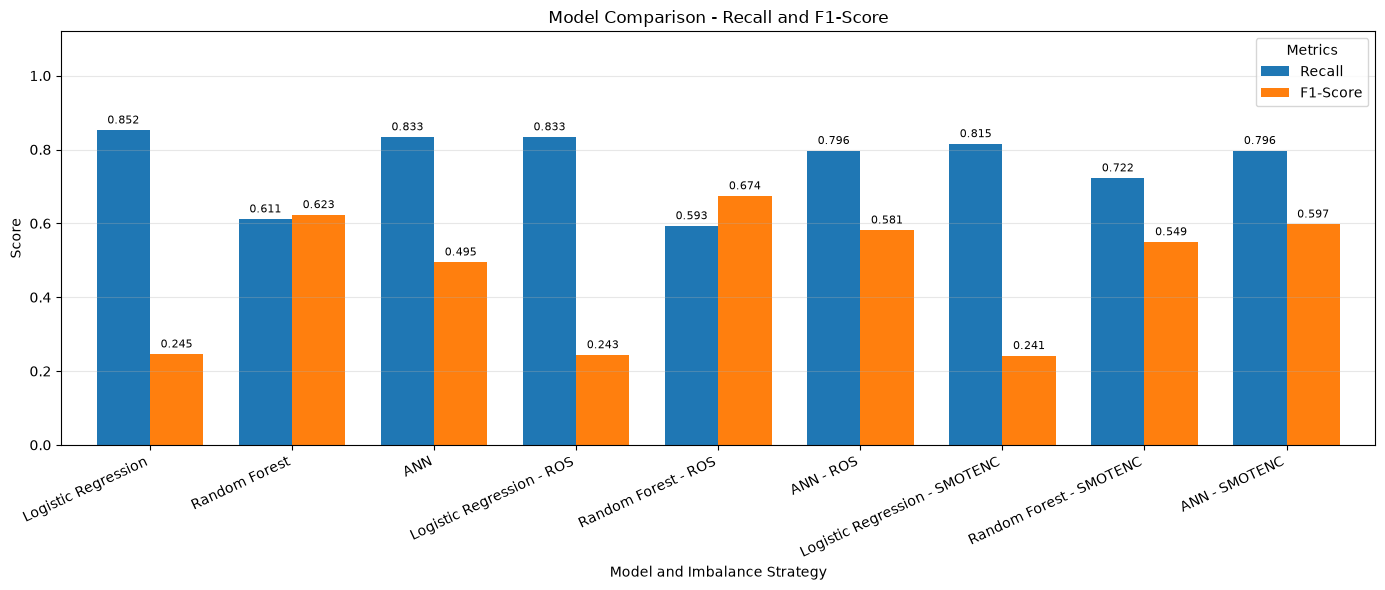

In [59]:

# Purpose: Compare Recall and F1-score across all imbalance experiments.

import matplotlib.pyplot as plt

comparison_plot = imbalance_comparison.set_index("Model")[
    ["Recall", "F1-Score"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.75
)

# Display values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.title("Model Comparison - Recall and F1-Score")
plt.xlabel("Model and Imbalance Strategy")
plt.ylabel("Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



#### SMOTENC — Model Evaluation and Findings

SMOTENC was applied to the original mixed-type training features to generate synthetic minority-class observations while preserving categorical feature validity.

**Key Observations:**

**1. Logistic Regression**
- SMOTENC did not improve the baseline performance.
- Recall decreased from 85.19% to 81.48%.
- F1-score decreased from 24.53% to 24.11%.

**2. Random Forest**
- Recall improved from 61.11% to 72.22%.
- Precision decreased from 63.46% to 44.32%.
- F1-score decreased from 62.26% to 54.93%.
- Random Oversampling achieved a better overall F1-score and PR-AUC.

**3. Artificial Neural Network**
- Precision improved from 35.16% to 47.78%.
- F1-score improved from 49.45% to 59.72%.
- Recall decreased from 83.33% to 79.63%.
- SMOTENC performed better than Random Oversampling in F1-score and PR-AUC.

**Overall Conclusion:**

SMOTENC produced different outcomes across the three algorithms. It improved failure detection for Random Forest and improved the precision-recall balance for ANN, but it did not provide meaningful benefits for Logistic Regression.

Random Oversampling produced the strongest Random Forest F1-score, while SMOTENC produced the strongest ANN F1-score among the tested imbalance strategies.

These findings demonstrate that the effectiveness of an imbalance-handling technique depends on the learning algorithm. No single resampling strategy consistently outperformed all alternatives.


### 2.6 — Hyperparameter Tuning

### Random Forest hyperparameter tuning


#### Random Forest — Hyperparameter Optimization

Random Forest with Random Oversampling demonstrated the strongest F1-score among our initial experiments.

We will use RandomizedSearchCV to explore different Random Forest configurations and identify a promising combination of hyperparameters.

**Experimental configuration:**

- Algorithm: Random Forest
- Imbalance handling: Random Oversampling
- Search strategy: RandomizedSearchCV
- Cross-validation: 5-fold StratifiedKFold
- Primary scoring metric: Average Precision (PR-AUC)
- Random state: 42

Preprocessing and oversampling will be performed inside the cross-validation pipeline to prevent data leakage.

The validation dataset will be used only after hyperparameter selection to assess the tuned model.


### Build the leakage-safe pipeline

In [60]:

# Purpose: Build a pipeline that performs preprocessing,
# Random Oversampling and Random Forest training within each CV fold.

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier

# Construct the complete training pipeline
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("oversampler", RandomOverSampler(random_state=42)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

print("Random Forest tuning pipeline created successfully.")


Random Forest tuning pipeline created successfully.


### Define the hyperparameter search

In [61]:

# Purpose: Define the Random Forest hyperparameter search space.

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

# Define hyperparameter combinations to explore
rf_param_distributions = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [None, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

# Configure stratified cross-validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initialize RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=rf_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("RandomizedSearchCV configured successfully.")
print("Number of parameter combinations:", 20)
print("Cross-validation folds:", 5)


RandomizedSearchCV configured successfully.
Number of parameter combinations: 20
Cross-validation folds: 5


#### Execute hyperparameter tuning

In [62]:

# Purpose: Search for the best Random Forest configuration
# using only the original training dataset.

rf_random_search.fit(X_train, y_train)

print("Random Forest hyperparameter tuning completed.")


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Random Forest hyperparameter tuning completed.


#### Inspect the best hyperparameters

In [63]:

# Purpose: Retrieve the best hyperparameters and cross-validation score.

print("Best Hyperparameters:\n")

for parameter, value in rf_random_search.best_params_.items():
    print(f"{parameter}: {value}")

print(
    "\nBest Cross-Validation PR-AUC:",
    round(rf_random_search.best_score_, 4)
)


Best Hyperparameters:

classifier__n_estimators: 300
classifier__min_samples_split: 10
classifier__min_samples_leaf: 2
classifier__max_features: log2
classifier__max_depth: 20

Best Cross-Validation PR-AUC: 0.7415


#### Evaluate the tuned Random Forest

In [64]:

# Purpose: Evaluate the best Random Forest pipeline on validation data.

# Retrieve the best fitted pipeline
rf_tuned_model = rf_random_search.best_estimator_

# Generate validation predictions
y_rf_tuned_pred = rf_tuned_model.predict(X_val)

# Generate failure probabilities
y_rf_tuned_prob = rf_tuned_model.predict_proba(X_val)[:, 1]

# Calculate validation metrics
rf_tuned_metrics = evaluate_model(
    "Random Forest - Tuned ROS",
    y_val,
    y_rf_tuned_pred,
    y_rf_tuned_prob
)

# Display results
display(pd.DataFrame([rf_tuned_metrics]).round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest - Tuned ROS,0.9806,0.7347,0.6667,0.699,0.9636,0.7585


### Confusion matrix and classification report

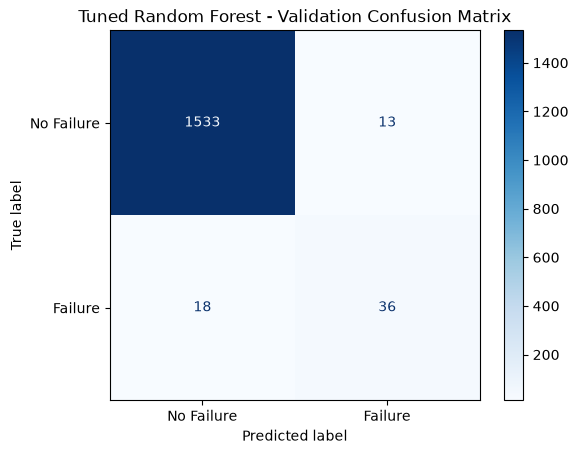

Classification Report:

              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1546
     Failure       0.73      0.67      0.70        54

    accuracy                           0.98      1600
   macro avg       0.86      0.83      0.84      1600
weighted avg       0.98      0.98      0.98      1600



In [65]:

# Purpose: Analyze the tuned Random Forest's validation predictions.

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Generate confusion matrix
rf_tuned_cm = confusion_matrix(y_val, y_rf_tuned_pred)

# Display confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=rf_tuned_cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues", values_format="d")

plt.title("Tuned Random Forest - Validation Confusion Matrix")
plt.show()

# Display classification report
print("Classification Report:\n")

print(
    classification_report(
        y_val,
        y_rf_tuned_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)


#### Compare Random Forest experiments

In [66]:

# Purpose: Compare baseline, Random Oversampling and tuned Random Forest.

rf_experiment_comparison = pd.DataFrame([
    rf_metrics,
    ros_results.loc[
        ros_results["Model"] == "Random Forest - ROS"
    ].iloc[0].to_dict(),
    smotenc_results.loc[
        smotenc_results["Model"] == "Random Forest - SMOTENC"
    ].iloc[0].to_dict(),
    rf_tuned_metrics
])

display(rf_experiment_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.9750,0.6346,0.6111,0.6226,0.9524,0.6866
1,Random Forest - ROS,0.9806,0.7805,0.5926,0.6737,0.9602,0.7159
2,Random Forest - SMOTENC,0.9600,0.4432,0.7222,0.5493,0.9657,0.6615
3,Random Forest - Tuned ROS,0.9806,0.7347,0.6667,0.6990,0.9636,0.7585



### Random Forest — Hyperparameter Tuning and Evaluation

RandomizedSearchCV with five-fold Stratified Cross-Validation was used to optimize the Random Forest model with Random Oversampling.

**Best Hyperparameters:**

- Number of estimators: 300
- Maximum depth: 20
- Minimum samples split: 10
- Minimum samples leaf: 2
- Maximum features: log2

The best cross-validation PR-AUC was 0.7415.

**Validation Performance:**

- Accuracy: 98.06%
- Precision: 73.47%
- Recall: 66.67%
- F1-Score: 69.90%
- ROC-AUC: 96.36%
- PR-AUC: 75.85%

**Key Observations:**

- The tuned model correctly identified 36 out of 54 actual machine failures.
- It generated 13 false positives and missed 18 actual failures.
- F1-score improved from 67.37% to 69.90% compared with the Random Forest + Random Oversampling experiment.
- PR-AUC improved from 71.59% to 75.85%.
- Recall improved from 59.26% to 66.67%.

**Conclusion:**

Hyperparameter tuning improved the overall performance of Random Forest with Random Oversampling. The tuned model achieved the highest F1-score and PR-AUC among the Random Forest experiments conducted so far.

These results demonstrate that appropriate hyperparameter selection can improve the balance between failure detection and false alarms.

The tuned Random Forest will be retained as a strong candidate for subsequent threshold optimization and final model comparison.

----------------------------------------------------------------------------------------

### Phase 2.7 — ANN Optimization Experiments


#### 2.7.1 ANN Learning-Rate Optimization

The learning rate controls how much the model updates its weights during training.

A learning rate that is too high may cause unstable learning, while a learning rate that is too low may result in slower convergence.

**Experiment:**

- Baseline learning rate: 0.001
- Experimental learning rate: 0.0001
- Optimizer: Adam
- Architecture: 64 and 32 neurons
- Activation functions: ReLU and Sigmoid
- Loss function: Binary Crossentropy
- Batch size: 32
- Maximum epochs: 50
- Imbalance handling: Class weights
- Early stopping: Enabled

Both configurations will be evaluated using three random seeds: 42, 52 and 62.

**Objective:** Determine whether reducing the learning rate improves ANN generalization and validation performance while keeping all other training settings consistent.


### Create a reusable ANN training function

In [67]:

# Purpose: Build a reusable function to train ANN models
# with different learning rates and random seeds.

import tensorflow as tf
import numpy as np
import pandas as pd

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

def train_ann_experiment(learning_rate, seed):

    # Set random seed for reproducibility
    tf.keras.utils.set_random_seed(seed)

    # Build the same baseline ANN architecture
    model = Sequential([
        Input(shape=(X_train_processed.shape[1],)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    # Compile the model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Configure early stopping
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    # Train the model using class weights
    history = model.fit(
        X_train_processed,
        y_train,
        validation_data=(X_val_processed, y_val),
        epochs=50,
        batch_size=32,
        class_weight=ann_class_weights,
        callbacks=[early_stopping],
        verbose=0
    )

    # Generate validation probabilities
    probabilities = model.predict(
        X_val_processed,
        verbose=0
    ).flatten()

    # Apply the default classification threshold
    predictions = (probabilities >= 0.50).astype(int)

    # Calculate validation metrics
    metrics = evaluate_model(
        f"ANN - LR {learning_rate} - Seed {seed}",
        y_val,
        predictions,
        probabilities
    )

    return model, history, metrics

print("ANN experiment function created successfully.")


ANN experiment function created successfully.


### Run learning-rate experiments

In [68]:

# Purpose: Compare two learning rates across three random seeds.

learning_rates = [0.001, 0.0001]
random_seeds = [42, 52, 62]

ann_lr_results = []
ann_lr_histories = {}
ann_lr_models = {}

for lr in learning_rates:

    for seed in random_seeds:

        print(f"Training ANN | Learning Rate: {lr} | Seed: {seed}")

        model, history, metrics = train_ann_experiment(
            learning_rate=lr,
            seed=seed
        )

        # Store model, history and evaluation results
        ann_lr_models[(lr, seed)] = model
        ann_lr_histories[(lr, seed)] = history
        ann_lr_results.append(metrics)

print("\nAll ANN learning-rate experiments completed.")


Training ANN | Learning Rate: 0.001 | Seed: 42
Training ANN | Learning Rate: 0.001 | Seed: 52
Training ANN | Learning Rate: 0.001 | Seed: 62
Training ANN | Learning Rate: 0.0001 | Seed: 42
Training ANN | Learning Rate: 0.0001 | Seed: 52
Training ANN | Learning Rate: 0.0001 | Seed: 62

All ANN learning-rate experiments completed.


### Compare individual experiment results

In [70]:
# Purpose: Display validation metrics for every learning-rate experiment.
ann_lr_comparison = pd.DataFrame(ann_lr_results)

display(ann_lr_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,ANN - LR 0.001 - Seed 42,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
1,ANN - LR 0.001 - Seed 52,0.9400,0.3433,0.8519,0.4894,0.9558,0.7184
2,ANN - LR 0.001 - Seed 62,0.9456,0.3613,0.7963,0.4971,0.9551,0.7336
3,ANN - LR 0.0001 - Seed 42,0.8844,0.2036,0.8333,0.3273,0.9425,0.5999
4,ANN - LR 0.0001 - Seed 52,0.8819,0.2000,0.8333,0.3226,0.9451,0.5842
5,ANN - LR 0.0001 - Seed 62,0.8775,0.1966,0.8519,0.3194,0.9517,0.6179


### Calculate mean and standard deviation

In [71]:

# Purpose: Compare average performance and variability
# across the three random seeds.

ann_lr_summary = (
    ann_lr_comparison
    .assign(
        Learning_Rate=ann_lr_comparison["Model"].str.extract(
            r"LR ([0-9.]+)"
        )[0].astype(float)
    )
    .groupby("Learning_Rate")[
        ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]
    ]
    .agg(["mean", "std"])
)

display(ann_lr_summary.round(4))


Accuracy         Precision          Recall         F1-Score  \
                  mean     std      mean     std    mean     std     mean   
Learning_Rate                                                               
0.0001          0.8812  0.0035    0.2001  0.0035  0.8395  0.0107   0.3231   
0.0010          0.9427  0.0028    0.3521  0.0090  0.8272  0.0283   0.4937   

                      ROC-AUC          PR-AUC          
                  std    mean     std    mean     std  
Learning_Rate                                          
0.0001         0.0039  0.9464  0.0047  0.6006  0.0168  
0.0010         0.0039  0.9557  0.0005  0.7282  0.0085

### Visualize learning-rate comparison

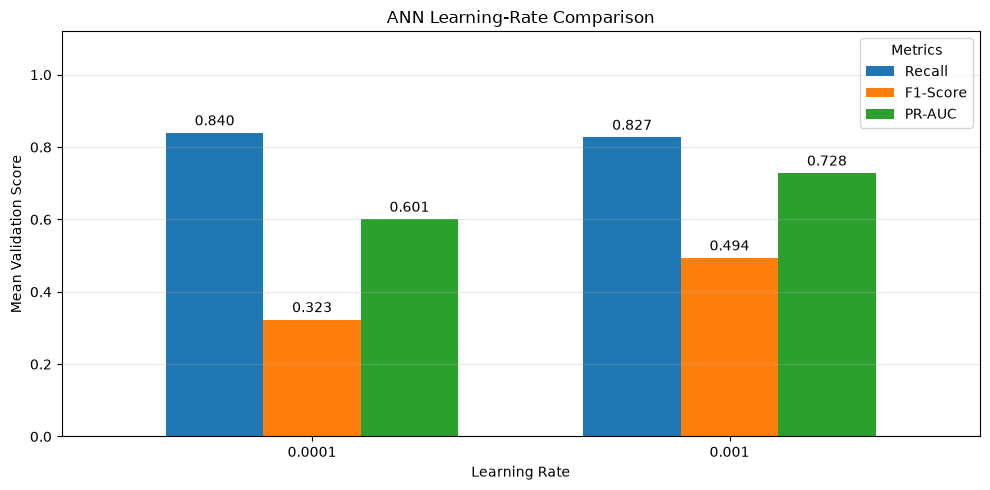

In [72]:

# Purpose: Visualize mean Recall, F1-score and PR-AUC
# for both learning-rate configurations.

ann_lr_plot_data = (
    ann_lr_comparison
    .assign(
        Learning_Rate=ann_lr_comparison["Model"].str.extract(
            r"LR ([0-9.]+)"
        )[0].astype(float)
    )
    .groupby("Learning_Rate")[
        ["Recall", "F1-Score", "PR-AUC"]
    ]
    .mean()
)

ax = ann_lr_plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

# Display metric values
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("ANN Learning-Rate Comparison")
plt.xlabel("Learning Rate")
plt.ylabel("Mean Validation Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Compare individual experiment results

In [73]:

# Purpose: Display validation metrics for every learning-rate experiment.

ann_lr_comparison = pd.DataFrame(ann_lr_results)

display(ann_lr_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,ANN - LR 0.001 - Seed 42,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
1,ANN - LR 0.001 - Seed 52,0.9400,0.3433,0.8519,0.4894,0.9558,0.7184
2,ANN - LR 0.001 - Seed 62,0.9456,0.3613,0.7963,0.4971,0.9551,0.7336
3,ANN - LR 0.0001 - Seed 42,0.8844,0.2036,0.8333,0.3273,0.9425,0.5999
4,ANN - LR 0.0001 - Seed 52,0.8819,0.2000,0.8333,0.3226,0.9451,0.5842
5,ANN - LR 0.0001 - Seed 62,0.8775,0.1966,0.8519,0.3194,0.9517,0.6179



#### ANN Learning-Rate Optimization — Experimental Findings

A controlled learning-rate experiment was conducted using three random seeds (42, 52 and 62) to investigate the impact of learning rate on ANN performance.

Two configurations were evaluated:

- Baseline learning rate: 0.001
- Experimental learning rate: 0.0001

All other ANN architecture and training parameters were kept unchanged.

**Mean Performance Results:**

| Metric | Learning Rate 0.001 | Learning Rate 0.0001 |
|---|---:|---:|
| Accuracy | 88.12% | 94.27% |
| Precision | 20.01% | 35.21% |
| Recall | 83.95% | 82.72% |
| F1-Score | 32.31% | 49.37% |
| ROC-AUC | 94.64% | 95.57% |
| PR-AUC | 60.06% | 72.82% |

**Key Observations:**

- Learning rate 0.001 achieved higher mean Precision, F1-score, ROC-AUC and PR-AUC.
- Learning rate 0.0001 achieved slightly higher mean Recall.
- The lower learning rate did not provide an overall performance improvement.
- Results across the three random seeds showed relatively consistent performance.

**Conclusion:**

The learning rate of 0.001 demonstrated better overall performance than 0.0001, particularly in F1-score and PR-AUC.

Therefore, the baseline learning rate of 0.001 will be retained for subsequent ANN experiments.

This experiment demonstrates that reducing the learning rate does not necessarily improve model performance and that learning-rate selection should be supported by validation results.



#### ANN Architecture Optimization

After identifying 0.001 as the preferred learning rate, we will investigate the impact of ANN architecture on machine failure prediction.

Two controlled architecture experiments will be conducted:

1. Increase hidden-layer neurons from 64 and 32 to 128 and 64.
2. Retain the baseline architecture and introduce Dropout regularization with a rate of 0.2.

**Experimental configuration:**
- Optimizer: Adam
- Learning rate: 0.001
- Activation: ReLU and Sigmoid
- Loss: Binary Crossentropy
- Batch size: 32
- Maximum epochs: 50
- Imbalance handling: Class weights
- Early stopping: Enabled

Only the architecture-related configuration will change between experiments.

**Objective:** Determine whether increasing network capacity or introducing Dropout improves ANN generalization and validation performance.


In [74]:

# Purpose: Train ANN models using different hidden-layer architectures.

from tensorflow.keras.layers import Dropout

def train_ann_architecture(hidden_units, dropout_rate=0, seed=42):

    tf.keras.utils.set_random_seed(seed)

    layers = [
        Input(shape=(X_train_processed.shape[1],)),
        Dense(hidden_units[0], activation="relu")
    ]

    # Add Dropout only when requested
    if dropout_rate > 0:
        layers.append(Dropout(dropout_rate))

    layers.append(Dense(hidden_units[1], activation="relu"))

    if dropout_rate > 0:
        layers.append(Dropout(dropout_rate))

    layers.append(Dense(1, activation="sigmoid"))

    model = Sequential(layers)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_processed,
        y_train,
        validation_data=(X_val_processed, y_val),
        epochs=50,
        batch_size=32,
        class_weight=ann_class_weights,
        callbacks=[early_stopping],
        verbose=0
    )

    probabilities = model.predict(
        X_val_processed,
        verbose=0
    ).flatten()

    predictions = (probabilities >= 0.50).astype(int)

    metrics = evaluate_model(
        "ANN Architecture Experiment",
        y_val,
        predictions,
        probabilities
    )

    return model, history, metrics

print("ANN architecture experiment function created successfully.")


ANN architecture experiment function created successfully.


In [75]:

# Purpose: Compare a larger ANN architecture against a Dropout ANN.

architecture_configs = {
    "ANN - 128/64": {
        "hidden_units": [128, 64],
        "dropout_rate": 0
    },
    "ANN - Dropout 0.2": {
        "hidden_units": [64, 32],
        "dropout_rate": 0.2
    }
}

ann_architecture_results = []
ann_architecture_models = {}
ann_architecture_histories = {}

for name, config in architecture_configs.items():

    print(f"Training: {name}")

    model, history, metrics = train_ann_architecture(
        hidden_units=config["hidden_units"],
        dropout_rate=config["dropout_rate"],
        seed=42
    )

    metrics["Model"] = name

    ann_architecture_models[name] = model
    ann_architecture_histories[name] = history
    ann_architecture_results.append(metrics)

print("\nANN architecture experiments completed.")


Training: ANN - 128/64
Training: ANN - Dropout 0.2

ANN architecture experiments completed.


#### Compare architecture results

In [78]:

# Purpose: Compare baseline ANN and architecture experiments.

ann_architecture_comparison = pd.DataFrame([
    ann_metrics,
    *ann_architecture_results
])

display(ann_architecture_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
1,ANN - 128/64,0.9431,0.3520,0.8148,0.4916,0.9522,0.6968
2,ANN - Dropout 0.2,0.9269,0.2968,0.8519,0.4402,0.9639,0.7129


#### Visualize architecture performance

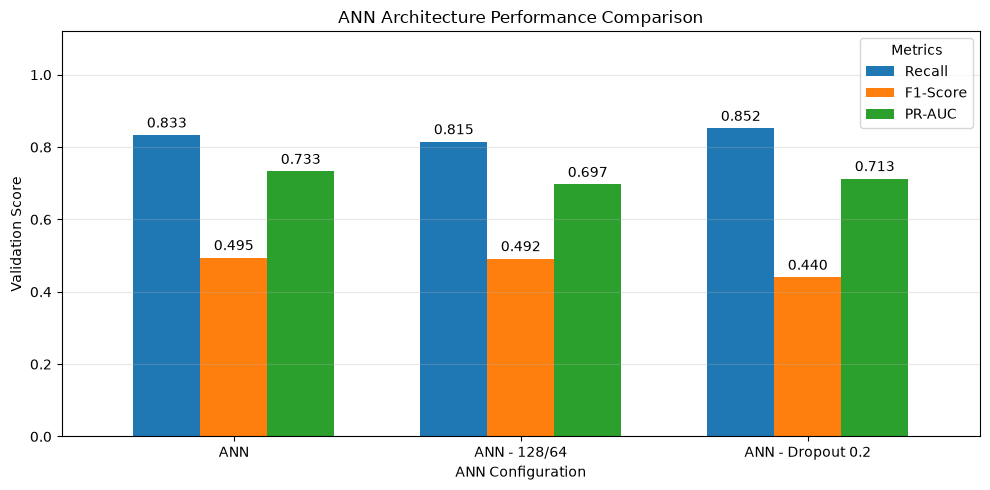

In [79]:

# Purpose: Compare Recall, F1-score and PR-AUC across ANN architectures.

architecture_plot = ann_architecture_comparison.set_index("Model")[
    ["Recall", "F1-Score", "PR-AUC"]
]

ax = architecture_plot.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("ANN Architecture Performance Comparison")
plt.xlabel("ANN Configuration")
plt.ylabel("Validation Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



#### ANN Architecture Optimization — Experimental Findings

Two ANN architecture experiments were conducted while keeping the learning rate, optimizer, loss function, batch size and class weights consistent.

**Configurations evaluated:**

1. Baseline ANN: 64 → 32 neurons.
2. Larger ANN: 128 → 64 neurons.
3. ANN with Dropout: 64 → 32 neurons with a Dropout rate of 0.2.

**Key Observations:**

- The larger architecture did not improve F1-score or PR-AUC compared with the baseline.
- Dropout achieved the highest Recall of 85.19% and ROC-AUC of 96.39%.
- However, Dropout reduced Precision to 29.68% and F1-score to 44.02%.
- The baseline ANN achieved the highest F1-score of 49.45% and PR-AUC of 73.28%.

**Conclusion:**

Neither architecture modification provided a consistent improvement over the baseline ANN.

The original architecture with 64 and 32 hidden neurons, ReLU activation, Adam optimizer and a learning rate of 0.001 will be retained as the preferred ANN configuration for subsequent evaluation.

This experiment demonstrates that increasing network complexity or introducing Dropout does not necessarily improve predictive performance.

---------------------------------------------------------------------------------------------------------


# Phase 3 — Model Evaluation and Reliability Analysis

This phase evaluates the reliability and generalization capability of the developed machine failure classification models.

The evaluation focuses on identifying the strengths and limitations of competing models using metrics appropriate for an imbalanced classification problem.

**Evaluation criteria:**

- Precision: Reliability of predicted machine failures.
- Recall: Ability to detect actual machine failures.
- F1-Score: Balance between Precision and Recall.
- ROC-AUC: Overall ranking ability across classification thresholds.
- PR-AUC: Performance in identifying the minority failure class.
- Confusion Matrix: Distribution of correct and incorrect predictions.

The validation dataset will be used for model comparison, error analysis and threshold selection. The independent test dataset will remain untouched until the final evaluation.

**Objective:** Identify a reliable model that balances missed machine failures against unnecessary maintenance inspections.


### Compare the strongest model configurations

In [80]:

# Purpose: Compare the strongest candidate configurations
# using their existing validation results.

selected_model_results = pd.DataFrame([
    lr_metrics,
    rf_tuned_metrics,
    ann_metrics,
    ros_results.loc[
        ros_results["Model"] == "ANN - ROS"
    ].iloc[0].to_dict(),
    smotenc_results.loc[
        smotenc_results["Model"] == "ANN - SMOTENC"
    ].iloc[0].to_dict()
])

display(
    selected_model_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197
1,Random Forest - Tuned ROS,0.9806,0.7347,0.6667,0.6990,0.9636,0.7585
2,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
3,ANN - ROS,0.9613,0.4574,0.7963,0.5811,0.9578,0.7070
4,ANN - SMOTENC,0.9637,0.4778,0.7963,0.5972,0.9566,0.7212


### Visualize candidate performance

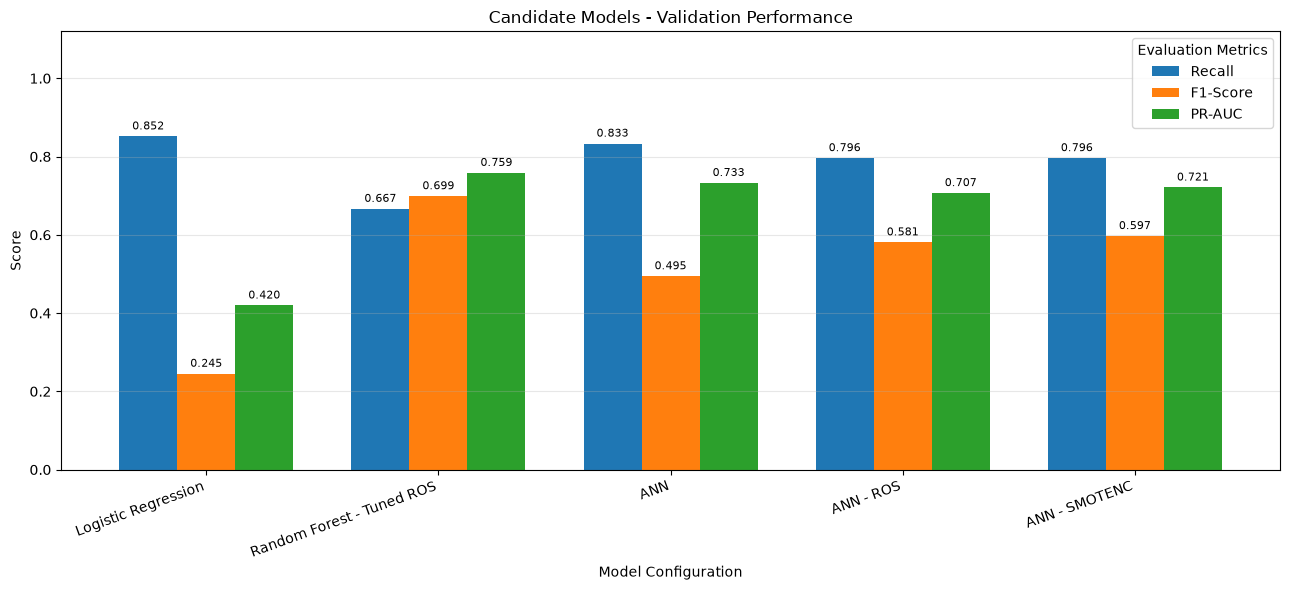

In [81]:

# Purpose: Compare Recall, F1-score and PR-AUC
# across the shortlisted model configurations.

phase3_plot = selected_model_results.set_index("Model")[
    ["Recall", "F1-Score", "PR-AUC"]
]

ax = phase3_plot.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.75
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.title("Candidate Models - Validation Performance")
plt.xlabel("Model Configuration")
plt.ylabel("Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### 3.2 Confusion Matrix and Error Analysis

A confusion matrix helps identify the types of prediction errors made by a classification model.

The analysis focuses on:

- True Positives (TP): Actual machine failures correctly detected.
- True Negatives (TN): Normal machine operations correctly identified.
- False Positives (FP): Normal machines incorrectly flagged for inspection.
- False Negatives (FN): Actual machine failures missed by the model.

False negatives may result in unexpected equipment downtime, while false positives can increase unnecessary inspection and maintenance costs.

**Objective:** Compare the operational error patterns of the tuned Random Forest and baseline ANN.


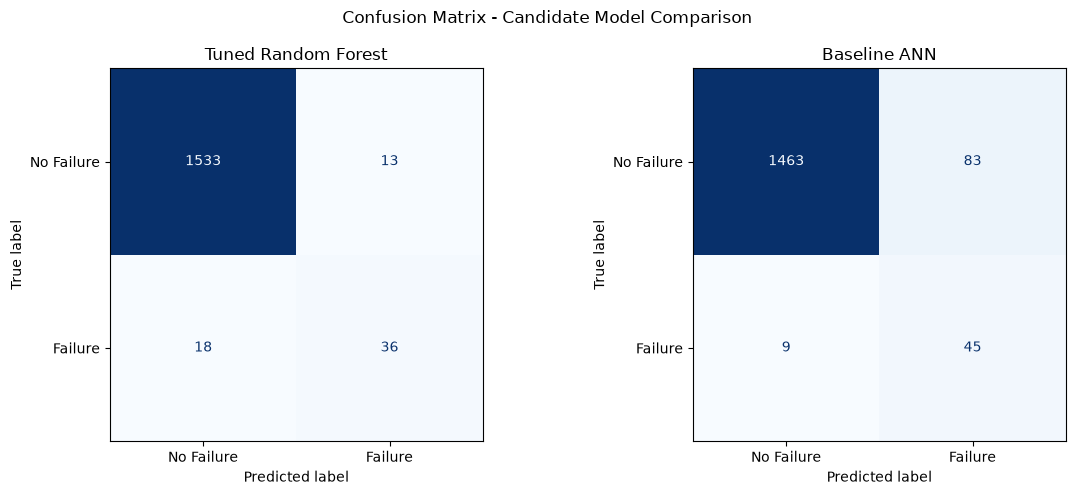

In [82]:

# Purpose: Compare confusion matrices of the two strongest candidates.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

candidate_predictions = {
    "Tuned Random Forest": y_rf_tuned_pred,
    "Baseline ANN": y_ann_val_pred
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, predictions) in zip(
    axes,
    candidate_predictions.items()
):
    cm = confusion_matrix(y_val, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Failure", "Failure"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.suptitle("Confusion Matrix - Candidate Model Comparison")
plt.tight_layout()
plt.show()


### Quantify prediction errors

In [83]:

# Purpose: Quantify prediction errors for the shortlisted models.

from sklearn.metrics import confusion_matrix
import pandas as pd

# Store candidate model predictions
candidate_predictions = {
    "Tuned Random Forest": y_rf_tuned_pred,
    "Baseline ANN": y_ann_val_pred
}

# Collect confusion matrix results
error_analysis = []

for model_name, predictions in candidate_predictions.items():

    # Extract confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate error-related metrics
    error_analysis.append({
        "Model": model_name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Total Predicted Failures": tp + fp,
        "Failure Detection Rate": round(
            tp / (tp + fn), 4
        ),
        "False Alarm Rate": round(
            fp / (fp + tn), 4
        )
    })

# Create and display comparison table
error_analysis_df = pd.DataFrame(error_analysis)

display(error_analysis_df)


,Model,True Negatives,False Positives,False Negatives,True Positives,Total Predicted Failures,Failure Detection Rate,False Alarm Rate
0,Tuned Random Forest,1533,13,18,36,49,0.6667,0.0084
1,Baseline ANN,1463,83,9,45,128,0.8333,0.0537



#### Confusion Matrix — Prediction Error Analysis

The confusion matrices of Tuned Random Forest and baseline ANN were compared to understand their operational prediction errors.

**Tuned Random Forest:**
- True Positives: 36
- True Negatives: 1,533
- False Positives: 13
- False Negatives: 18
- Failure Detection Rate: 66.67%
- False Alarm Rate: 0.84%

**Baseline ANN:**
- True Positives: 45
- True Negatives: 1,463
- False Positives: 83
- False Negatives: 9
- Failure Detection Rate: 83.33%
- False Alarm Rate: 5.37%

**Conclusion:**

Tuned Random Forest produces fewer false alarms and offers higher precision, while ANN detects more actual machine failures and produces fewer false negatives.

For predictive maintenance, missed failures can lead to unexpected equipment downtime and operational losses. Therefore, the cost of false negatives must be considered alongside inspection costs when selecting the final model and decision threshold.



### 3.3 Decision-Threshold Sensitivity Analysis

Classification models generate probability scores, which are converted into binary predictions using a decision threshold.

The default threshold of 0.50 is not necessarily optimal for predictive maintenance because machine failures are relatively rare and missed failures may result in significant operational losses.

- Lower thresholds generally increase Recall but may also increase false alarms.
- Higher thresholds generally increase Precision but may miss more actual failures.

**Objective:** Evaluate multiple decision thresholds and identify how Precision, Recall and F1-score change for the Tuned Random Forest and baseline ANN.


### Evaluate multiple decision thresholds

In [84]:

# Purpose: Evaluate threshold sensitivity for the tuned Random Forest
# and baseline ANN using validation probabilities.

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Define decision thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

# Store validation probabilities for candidate models
candidate_probabilities = {
    "Tuned Random Forest": y_rf_tuned_prob,
    "Baseline ANN": y_ann_val_prob
}

threshold_results = []

# Evaluate each model at different thresholds
for model_name, probabilities in candidate_probabilities.items():

    for threshold in thresholds:

        # Convert probabilities into binary predictions
        predictions = (
            probabilities >= threshold
        ).astype(int)

        # Calculate evaluation metrics
        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-Score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

# Create threshold comparison DataFrame
threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))


,Model,Threshold,Precision,Recall,F1-Score
0,Tuned Random Forest,0.10,0.2701,0.8704,0.4123
1,Tuned Random Forest,0.15,0.3310,0.8704,0.4796
2,Tuned Random Forest,0.20,0.3982,0.8333,0.5389
3,Tuned Random Forest,0.25,0.4824,0.7593,0.5899
4,Tuned Random Forest,0.30,0.5195,0.7407,0.6107
5,Tuned Random Forest,0.35,0.5652,0.7222,0.6341
6,Tuned Random Forest,0.40,0.6316,0.6667,0.6486
7,Tuned Random Forest,0.45,0.6923,0.6667,0.6792
8,Tuned Random Forest,0.50,0.7347,0.6667,0.6990
9,Tuned Random Forest,0.55,0.7447,0.6481,0.6931


### Visualize threshold sensitivity

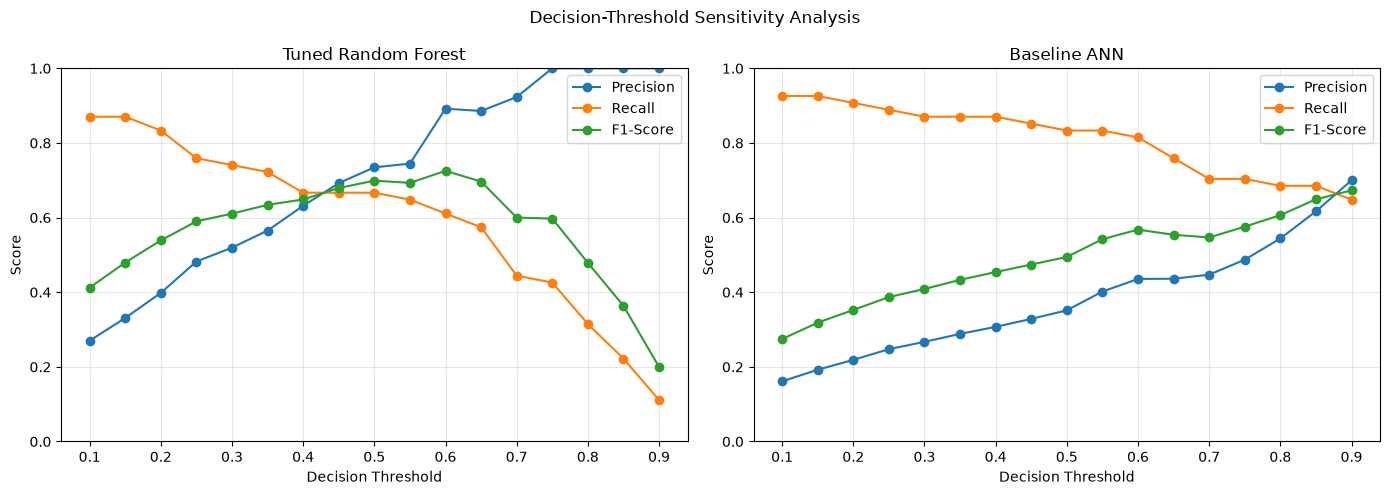

In [85]:

# Purpose: Visualize how Precision, Recall and F1-score
# change across different decision thresholds.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model_name in zip(
    axes,
    candidate_probabilities.keys()
):

    # Filter results for the current model
    model_data = threshold_results_df[
        threshold_results_df["Model"] == model_name
    ]

    # Plot evaluation metrics
    ax.plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="o",
        label="Precision"
    )

    ax.plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="o",
        label="Recall"
    )

    ax.plot(
        model_data["Threshold"],
        model_data["F1-Score"],
        marker="o",
        label="F1-Score"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Decision-Threshold Sensitivity Analysis")
plt.tight_layout()
plt.show()


### Identify the best F1-score threshold

In [86]:

# Purpose: Identify the threshold that maximizes F1-score
# for each candidate model on the validation dataset.

best_f1_thresholds = (
    threshold_results_df
    .loc[
        threshold_results_df.groupby("Model")["F1-Score"].idxmax()
    ]
    .reset_index(drop=True)
)

print("Best F1-score Threshold for Each Model:\n")

display(best_f1_thresholds.round(4))


Best F1-score Threshold for Each Model:



,Model,Threshold,Precision,Recall,F1-Score
0,Baseline ANN,0.9,0.7000,0.6481,0.6731
1,Tuned Random Forest,0.6,0.8919,0.6111,0.7253


### Compare threshold 0.50 with the best F1 threshold

In [87]:

# Purpose: Compare default threshold performance against
# the best F1-score threshold for each candidate model.

threshold_comparison = []

for _, row in best_f1_thresholds.iterrows():

    model_name = row["Model"]

    default_result = threshold_results_df[
        (threshold_results_df["Model"] == model_name) &
        (threshold_results_df["Threshold"] == 0.50)
    ].iloc[0]

    threshold_comparison.append({
        "Model": model_name,
        "Default Threshold": 0.50,
        "Default Precision": default_result["Precision"],
        "Default Recall": default_result["Recall"],
        "Default F1-Score": default_result["F1-Score"],
        "Best F1 Threshold": row["Threshold"],
        "Best Precision": row["Precision"],
        "Best Recall": row["Recall"],
        "Best F1-Score": row["F1-Score"]
    })

threshold_comparison_df = pd.DataFrame(threshold_comparison)

display(threshold_comparison_df.round(4))


,Model,Default Threshold,Default Precision,Default Recall,Default F1-Score,Best F1 Threshold,Best Precision,Best Recall,Best F1-Score
0,Baseline ANN,0.5,0.3516,0.8333,0.4945,0.9,0.7000,0.6481,0.6731
1,Tuned Random Forest,0.5,0.7347,0.6667,0.6990,0.6,0.8919,0.6111,0.7253



### 3.4 Cost-Based Decision Threshold Selection

The best F1-score threshold does not necessarily minimize operational costs.

In predictive maintenance:
- False positives may result in unnecessary machine inspections and maintenance expenses.
- False negatives may result in unexpected equipment failures, production downtime and repair costs.

For this experiment, the following hypothetical cost assumptions are used:

- False Positive cost: ₹2,000
- False Negative cost: ₹50,000

The total estimated cost is calculated as:

Total Cost = (False Positives × FP Cost) + (False Negatives × FN Cost)

**Objective:** Identify the decision threshold that minimizes estimated operational costs for the Tuned Random Forest and baseline ANN.

These hypothetical costs are used for analytical comparison and should be validated with actual industrial cost information before deployment.


In [88]:

# Purpose: Calculate hypothetical operational costs
# for both candidate models across all tested thresholds.

from sklearn.metrics import confusion_matrix

# Define hypothetical business costs
FP_COST = 2000
FN_COST = 50000

cost_results = []

for model_name, probabilities in candidate_probabilities.items():

    for threshold in thresholds:

        # Generate predictions for the current threshold
        predictions = (probabilities >= threshold).astype(int)

        # Calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        # Calculate total estimated cost
        total_cost = (
            fp * FP_COST +
            fn * FN_COST
        )

        cost_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp,
            "True Negatives": tn,
            "FP Cost": fp * FP_COST,
            "FN Cost": fn * FN_COST,
            "Total Estimated Cost": total_cost
        })

cost_results_df = pd.DataFrame(cost_results)

display(cost_results_df)


,Model,Threshold,False Positives,False Negatives,True Positives,True Negatives,FP Cost,FN Cost,Total Estimated Cost
0,Tuned Random Forest,0.10,127,7,47,1419,254000,350000,604000
1,Tuned Random Forest,0.15,95,7,47,1451,190000,350000,540000
2,Tuned Random Forest,0.20,68,9,45,1478,136000,450000,586000
3,Tuned Random Forest,0.25,44,13,41,1502,88000,650000,738000
4,Tuned Random Forest,0.30,37,14,40,1509,74000,700000,774000
5,Tuned Random Forest,0.35,30,15,39,1516,60000,750000,810000
6,Tuned Random Forest,0.40,21,18,36,1525,42000,900000,942000
7,Tuned Random Forest,0.45,16,18,36,1530,32000,900000,932000
8,Tuned Random Forest,0.50,13,18,36,1533,26000,900000,926000
9,Tuned Random Forest,0.55,12,19,35,1534,24000,950000,974000


In [89]:

# Purpose: Identify the minimum-cost threshold for each candidate model.

best_cost_thresholds = (
    cost_results_df
    .loc[
        cost_results_df.groupby("Model")[
            "Total Estimated Cost"
        ].idxmin()
    ]
    .reset_index(drop=True)
)

print("Minimum-Cost Threshold for Each Model:\n")
display(best_cost_thresholds)


Minimum-Cost Threshold for Each Model:



,Model,Threshold,False Positives,False Negatives,True Positives,True Negatives,FP Cost,FN Cost,Total Estimated Cost
0,Baseline ANN,0.40,106,7,47,1440,212000,350000,562000
1,Tuned Random Forest,0.15,95,7,47,1451,190000,350000,540000


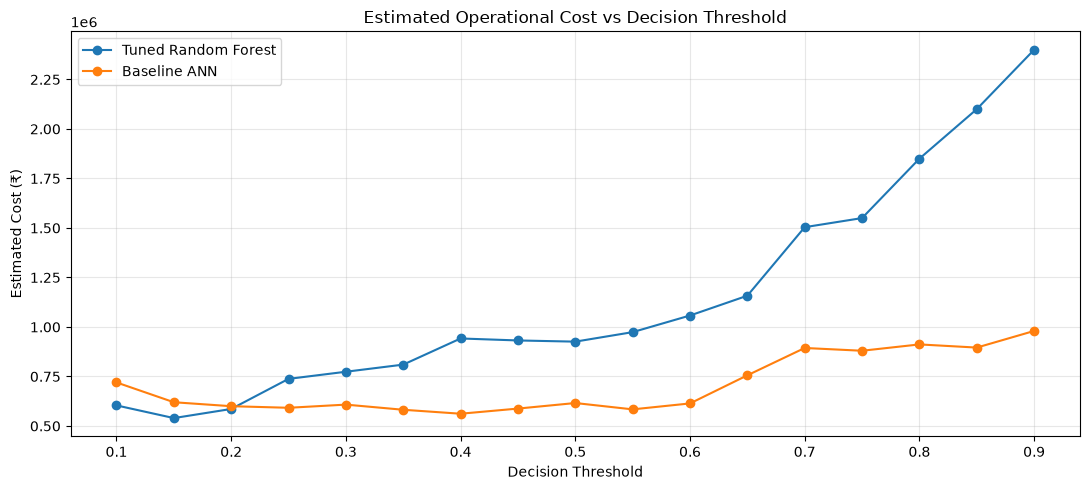

In [91]:

# Purpose: Compare estimated operational costs across decision thresholds.

fig, ax = plt.subplots(figsize=(11, 5))

for model_name in candidate_probabilities.keys():

    model_data = cost_results_df[
        cost_results_df["Model"] == model_name
    ]

    ax.plot(
        model_data["Threshold"],
        model_data["Total Estimated Cost"],
        marker="o",
        label=model_name
    )

ax.set_title("Estimated Operational Cost vs Decision Threshold")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Estimated Cost (₹)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



#### 3.4 Cost-Based Threshold Selection — Findings

A cost-based threshold analysis was conducted using the following hypothetical business assumptions:

- False Positive cost: ₹2,000
- False Negative cost: ₹50,000

**Minimum-Cost Results:**

| Model | Threshold | False Positives | False Negatives | Estimated Cost |
|---|---:|---:|---:|---:|
| Tuned Random Forest | 0.15 | 95 | 7 | ₹5,40,000 |
| Baseline ANN | 0.40 | 106 | 7 | ₹5,62,000 |

**Key Observations:**

- Tuned Random Forest achieved the lowest estimated cost of ₹5,40,000.
- Both models detected 47 out of 54 actual failures at their respective minimum-cost thresholds.
- Random Forest generated 11 fewer false alarms than ANN.
- Random Forest reduced estimated costs by ₹22,000 compared with ANN.

**Conclusion:**

Under the assumed cost structure, Tuned Random Forest with a decision threshold of 0.15 is the preferred operational configuration.

The lower threshold prioritizes detecting machine failures, accepting additional false alarms to reduce the number of missed failures.

The selected threshold is based on validation data and hypothetical costs. Actual industrial cost information and independent test evaluation would be required before deployment.

---------------------------------------------------------------------------------------------------------------


### 3.5 Overfitting and Model Reliability Analysis

Overfitting occurs when a model learns the training data too closely and performs poorly on unseen observations.

To assess model reliability, we will compare training and validation performance and examine the cross-validation results.

**Evaluation approach:**

- Calculate training metrics for the tuned Random Forest.
- Compare training and validation Precision, Recall, F1-score and PR-AUC.
- Examine the cross-validation PR-AUC against validation PR-AUC.
- Identify potential differences between training and unseen-data performance.

**Objective:** Assess whether the selected model demonstrates reasonable generalization capability and identify potential overfitting.


### Compare training and validation performance

In [92]:

# Purpose: Compare tuned Random Forest performance on original
# training data and validation data.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Training predictions on the original, non-resampled training data
y_rf_train_pred = rf_tuned_model.predict(X_train)
y_rf_train_prob = rf_tuned_model.predict_proba(X_train)[:, 1]

# Validation predictions already generated
y_rf_validation_pred = y_rf_tuned_pred
y_rf_validation_prob = y_rf_tuned_prob

# Calculate metrics for both datasets
def calculate_reliability_metrics(y_true, predictions, probabilities):

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    }

rf_reliability_comparison = pd.DataFrame([
    {
        "Dataset": "Training",
        **calculate_reliability_metrics(
            y_train, y_rf_train_pred, y_rf_train_prob
        )
    },
    {
        "Dataset": "Validation",
        **calculate_reliability_metrics(
            y_val, y_rf_validation_pred, y_rf_validation_prob
        )
    }
])

display(rf_reliability_comparison.round(4))


,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Training,0.9994,0.9819,1.0000,0.9909,1.0000,1.0000
1,Validation,0.9806,0.7347,0.6667,0.6990,0.9636,0.7585


### Calculate training-validation performance gaps

In [93]:

# Purpose: Quantify the difference between training and
# validation performance for the tuned Random Forest.

reliability_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

train_scores = (
    rf_reliability_comparison
    .set_index("Dataset")
    .loc["Training", reliability_metrics]
)

validation_scores = (
    rf_reliability_comparison
    .set_index("Dataset")
    .loc["Validation", reliability_metrics]
)

reliability_gap = pd.DataFrame({
    "Training Score": train_scores,
    "Validation Score": validation_scores,
    "Absolute Gap": (
        train_scores - validation_scores
    ).abs()
})

print("Training vs Validation Performance Gap:\n")
display(reliability_gap.round(4))

print(
    "\nBest Cross-Validation PR-AUC:",
    round(rf_random_search.best_score_, 4)
)

print(
    "Validation PR-AUC:",
    round(average_precision_score(y_val, y_rf_validation_prob), 4)
)


Training vs Validation Performance Gap:



,Training Score,Validation Score,Absolute Gap
Accuracy,0.9994,0.9806,0.0188
Precision,0.9819,0.7347,0.2472
Recall,1.0000,0.6667,0.3333
F1-Score,0.9909,0.6990,0.2918
ROC-AUC,1.0000,0.9636,0.0364
PR-AUC,1.0000,0.7585,0.2415



Best Cross-Validation PR-AUC: 0.7415
Validation PR-AUC: 0.7585


### Visualize generalization performance

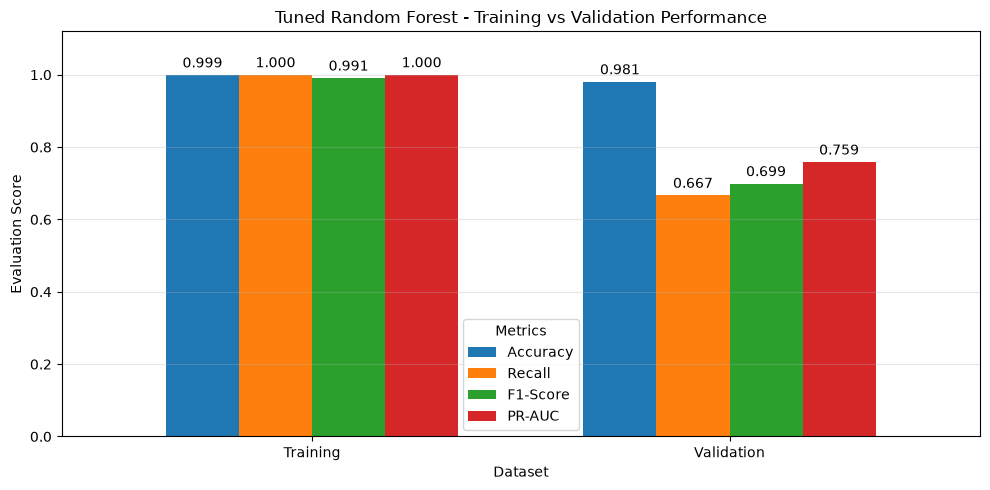

In [95]:

# Purpose: Visualize training and validation performance
# to identify potential overfitting and generalization gaps.

reliability_plot = rf_reliability_comparison.set_index("Dataset")[
    ["Accuracy", "Recall", "F1-Score", "PR-AUC"]
]

ax = reliability_plot.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.7
)

# Display metric values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("Tuned Random Forest - Training vs Validation Performance")
plt.xlabel("Dataset")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



#### 3.5 Overfitting and Model Reliability Analysis

The tuned Random Forest was evaluated on both the original training dataset and the validation dataset to investigate its generalization capability.

**Training Performance:**
- Accuracy: 99.94%
- Recall: 100%
- F1-Score: 99.09%
- PR-AUC: 100%

**Validation Performance:**
- Accuracy: 98.06%
- Recall: 66.67%
- F1-Score: 69.90%
- PR-AUC: 75.85%

**Key Observations:**

- The model achieved near-perfect performance on the training dataset.
- A noticeable reduction in Recall, F1-score and PR-AUC was observed on validation data.
- The difference between training and validation performance indicates potential overfitting.
- Cross-validation PR-AUC of 74.15% was reasonably close to validation PR-AUC of 75.85%.

**Conclusion:**

Although the tuned Random Forest demonstrates strong validation performance, the difference between training and validation metrics indicates potential overfitting.

The model should therefore be evaluated on the independent test dataset before making a final deployment recommendation. Further monitoring and validation using real industrial data would also be necessary.

-------------------------------------------------------------------------------------------


### 3.6 Final Independent Test Evaluation

The selected Tuned Random Forest model is evaluated using the independent test dataset to assess its performance on previously unseen observations.

**Selected configuration:**
- Model: Tuned Random Forest with Random Oversampling.
- Decision threshold: 0.15.
- Threshold selection: Minimum estimated validation cost.
- Evaluation dataset: Original, untouched test dataset.

The selected model and decision threshold are kept fixed during this evaluation.

**Evaluation metrics:**
- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- PR-AUC
- Confusion Matrix

**Objective:** Assess the final model's generalization performance and determine whether its failure detection capability remains reliable on unseen machine observations.


#### Generate final test predictions

In [96]:

# Purpose: Generate independent test predictions using the selected
# tuned Random Forest model and validation-selected threshold.

# Generate failure probabilities from the untouched test data
y_rf_test_prob = rf_tuned_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
FINAL_THRESHOLD = 0.15

y_rf_test_pred = (
    y_rf_test_prob >= FINAL_THRESHOLD
).astype(int)

print("Final test predictions generated successfully.")
print("Selected decision threshold:", FINAL_THRESHOLD)
print("Test observations:", len(y_test))


Final test predictions generated successfully.
Selected decision threshold: 0.15
Test observations: 2000


#### Calculate final test metrics

In [97]:

# Purpose: Evaluate the selected model using independent test data.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_test_metrics = {
    "Model": "Tuned Random Forest - ROS",
    "Threshold": FINAL_THRESHOLD,
    "Accuracy": accuracy_score(y_test, y_rf_test_pred),
    "Precision": precision_score(
        y_test, y_rf_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_rf_test_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_rf_test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_rf_test_prob),
    "PR-AUC": average_precision_score(y_test, y_rf_test_prob)
}

final_test_results = pd.DataFrame([final_test_metrics])

display(final_test_results.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Tuned Random Forest - ROS,0.15,0.9485,0.3871,0.8824,0.5381,0.9639,0.7605


### Final test confusion matrix

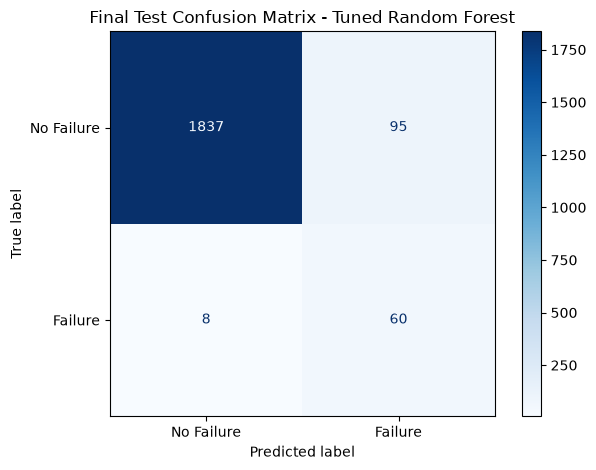

Classification Report:

              precision    recall  f1-score   support

  No Failure       1.00      0.95      0.97      1932
     Failure       0.39      0.88      0.54        68

    accuracy                           0.95      2000
   macro avg       0.69      0.92      0.76      2000
weighted avg       0.97      0.95      0.96      2000



In [98]:

# Purpose: Examine correct predictions and errors on the independent test set.

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

final_test_cm = confusion_matrix(
    y_test,
    y_rf_test_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = final_test_cm.ravel()

ConfusionMatrixDisplay(
    confusion_matrix=final_test_cm,
    display_labels=["No Failure", "Failure"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Final Test Confusion Matrix - Tuned Random Forest")
plt.tight_layout()
plt.show()

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_rf_test_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)


### Calculate hypothetical test operational cost

In [99]:

# Purpose: Estimate hypothetical operational costs
# using the final independent test predictions.

FP_COST = 2000
FN_COST = 50000

test_fp_cost = fp * FP_COST
test_fn_cost = fn * FN_COST

test_total_cost = test_fp_cost + test_fn_cost

final_test_cost = pd.DataFrame([{
    "Threshold": FINAL_THRESHOLD,
    "True Positives": tp,
    "True Negatives": tn,
    "False Positives": fp,
    "False Negatives": fn,
    "False Positive Cost": test_fp_cost,
    "False Negative Cost": test_fn_cost,
    "Total Estimated Cost": test_total_cost
}])

display(final_test_cost)


,Threshold,True Positives,True Negatives,False Positives,False Negatives,False Positive Cost,False Negative Cost,Total Estimated Cost
0,0.15,60,1837,95,8,190000,400000,590000


### Compare validation and test performance

In [100]:

# Purpose: Compare validation and independent test performance
# using the same selected model and decision threshold.

validation_at_selected_threshold = (
    threshold_results_df[
        (threshold_results_df["Model"] == "Tuned Random Forest") &
        (threshold_results_df["Threshold"] == FINAL_THRESHOLD)
    ].iloc[0]
)

validation_test_comparison = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Precision": validation_at_selected_threshold["Precision"],
        "Recall": validation_at_selected_threshold["Recall"],
        "F1-Score": validation_at_selected_threshold["F1-Score"],
        "ROC-AUC": roc_auc_score(y_val, y_rf_tuned_prob),
        "PR-AUC": average_precision_score(y_val, y_rf_tuned_prob)
    },
    {
        "Dataset": "Test",
        "Precision": final_test_metrics["Precision"],
        "Recall": final_test_metrics["Recall"],
        "F1-Score": final_test_metrics["F1-Score"],
        "ROC-AUC": final_test_metrics["ROC-AUC"],
        "PR-AUC": final_test_metrics["PR-AUC"]
    }
])

display(validation_test_comparison.round(4))


,Dataset,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Validation,0.3310,0.8704,0.4796,0.9636,0.7585
1,Test,0.3871,0.8824,0.5381,0.9639,0.7605



#### 3.6 Final Independent Test Evaluation — Findings

The selected Tuned Random Forest model with Random Oversampling was evaluated on the independent test dataset using the validation-selected decision threshold of 0.15.

**Final Test Metrics:**

- Accuracy: 94.85%
- Precision: 38.71%
- Recall: 88.24%
- F1-Score: 53.81%
- ROC-AUC: 96.39%
- PR-AUC: 76.05%

**Confusion Matrix:**

- True Positives: 60
- True Negatives: 1,837
- False Positives: 95
- False Negatives: 8

**Hypothetical Operational Cost:**

- False Positive Cost: ₹1,90,000
- False Negative Cost: ₹4,00,000
- Total Estimated Cost: ₹5,90,000

**Key Observations:**

- The model successfully detected 60 out of 68 actual machine failures.
- Only 8 actual failures were missed.
- The test Recall of 88.24% was slightly higher than the validation Recall of 87.04%.
- ROC-AUC and PR-AUC remained consistent between validation and test datasets.
- The model generated 95 false alarms, indicating that inspection workload remains an important operational consideration.

**Conclusion:**

The tuned Random Forest demonstrated encouraging generalization performance on independent test data.

With a decision threshold of 0.15, the model achieved 88.24% Recall, demonstrating its ability to identify most machine failures.

Although false positives remain relatively high, the model provides a promising predictive maintenance solution under the assumed business cost structure.

The hypothetical cost estimates should be validated against actual industrial maintenance and downtime expenses before deployment.

--------------------------------------------------------------------------------------


# Phase 4 — Research and Controlled Experimentation

This phase investigates whether an Artificial Neural Network consistently outperforms traditional machine learning models for predicting machine failures.

The experiments focus on understanding how ANN configuration choices influence predictive performance and whether observed improvements are consistent across repeated runs.

**Research Question:**

Does an ANN consistently outperform traditional machine learning models in predicting rare machine failure events?

**Null Hypothesis (H0):**

The ANN does not demonstrate consistently better predictive performance than traditional machine learning models.

**Alternative Hypothesis (H1):**

The ANN demonstrates better predictive performance than traditional machine learning models, particularly in identifying machine failures.

**Experimental Approach:**

- Compare ANN performance with Logistic Regression and Random Forest.
- Evaluate different ANN learning rates while keeping other conditions stable.
- Compare ANN architectures and investigate the effect of Dropout.
- Repeat learning-rate experiments using multiple random seeds.
- Analyze mean performance, standard deviation and consistency.

**Primary evaluation metrics:** Recall, F1-Score and PR-AUC.



### 4.2 Experimental Design and Controlled Variables

The controlled experiments were designed to investigate the effect of ANN configuration changes on machine failure prediction.

**Experiment 1 — Learning Rate Comparison**

Two learning rates were evaluated:

- 0.001
- 0.0001

The following conditions were kept consistent:

- ANN architecture: 64 → 32 hidden neurons.
- Activation functions: ReLU and Sigmoid.
- Optimizer: Adam.
- Loss function: Binary Crossentropy.
- Batch size: 32.
- Training epochs: 50.
- Class imbalance handling: Class weights.
- Random seeds: 42, 52 and 62.

**Experiment 2 — Architecture Comparison**

Three configurations were compared:

- Baseline ANN: 64 → 32 neurons.
- Larger ANN: 128 → 64 neurons.
- ANN with Dropout: 64 → 32 neurons with Dropout rate 0.2.

The purpose was to investigate whether increasing network capacity or introducing regularization improves generalization.

**Evaluation Metrics:**

Accuracy, Precision, Recall, F1-Score, ROC-AUC and PR-AUC.

The validation dataset was used for experimental comparisons. The independent test dataset was not used for experiment selection.


### 4.3 — Controlled Experiment 1: Learning Rate 

#### Record individual experiment results

In [102]:

# Purpose: Consolidate the recorded ANN learning-rate experiment results.

ann_lr_results_df = pd.DataFrame([
    {
        "Learning Rate": 0.001,
        "Random Seed": 42,
        "Accuracy": 0.9425,
        "Precision": 0.3516,
        "Recall": 0.8333,
        "F1-Score": 0.4945,
        "ROC-AUC": 0.9561,
        "PR-AUC": 0.7328
    },
    {
        "Learning Rate": 0.001,
        "Random Seed": 52,
        "Accuracy": 0.9400,
        "Precision": 0.3433,
        "Recall": 0.8519,
        "F1-Score": 0.4894,
        "ROC-AUC": 0.9558,
        "PR-AUC": 0.7184
    },
    {
        "Learning Rate": 0.001,
        "Random Seed": 62,
        "Accuracy": 0.9456,
        "Precision": 0.3613,
        "Recall": 0.7963,
        "F1-Score": 0.4971,
        "ROC-AUC": 0.9551,
        "PR-AUC": 0.7336
    },
    {
        "Learning Rate": 0.0001,
        "Random Seed": 42,
        "Accuracy": 0.8844,
        "Precision": 0.2036,
        "Recall": 0.8333,
        "F1-Score": 0.3273,
        "ROC-AUC": 0.9425,
        "PR-AUC": 0.5999
    },
    {
        "Learning Rate": 0.0001,
        "Random Seed": 52,
        "Accuracy": 0.8819,
        "Precision": 0.2000,
        "Recall": 0.8333,
        "F1-Score": 0.3226,
        "ROC-AUC": 0.9451,
        "PR-AUC": 0.5842
    },
    {
        "Learning Rate": 0.0001,
        "Random Seed": 62,
        "Accuracy": 0.8775,
        "Precision": 0.1966,
        "Recall": 0.8519,
        "F1-Score": 0.3194,
        "ROC-AUC": 0.9517,
        "PR-AUC": 0.6179
    }
])

display(ann_lr_results_df.round(4))


,Learning Rate,Random Seed,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,0.0010,42,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
1,0.0010,52,0.9400,0.3433,0.8519,0.4894,0.9558,0.7184
2,0.0010,62,0.9456,0.3613,0.7963,0.4971,0.9551,0.7336
3,0.0001,42,0.8844,0.2036,0.8333,0.3273,0.9425,0.5999
4,0.0001,52,0.8819,0.2000,0.8333,0.3226,0.9451,0.5842
5,0.0001,62,0.8775,0.1966,0.8519,0.3194,0.9517,0.6179


### Calculate mean and standard deviation

In [103]:

# Purpose: Measure average performance and variability
# across the three random seeds for each learning rate.

experiment_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

ann_lr_summary = (
    ann_lr_results_df
    .groupby("Learning Rate")[experiment_metrics]
    .agg(["mean", "std"])
)

display(ann_lr_summary.round(4))


Accuracy         Precision          Recall         F1-Score  \
                  mean     std      mean     std    mean     std     mean   
Learning Rate                                                               
0.0001          0.8813  0.0035    0.2001  0.0035  0.8395  0.0107   0.3231   
0.0010          0.9427  0.0028    0.3521  0.0090  0.8272  0.0283   0.4937   

                      ROC-AUC          PR-AUC          
                  std    mean     std    mean     std  
Learning Rate                                          
0.0001         0.0040  0.9464  0.0047  0.6007  0.0169  
0.0010         0.0039  0.9557  0.0005  0.7283  0.0086

#### Visualize learning-rate performance

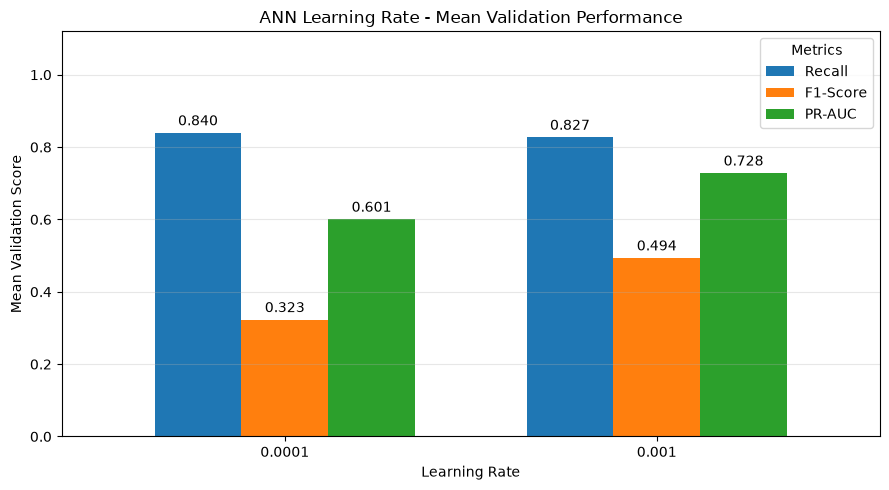

In [104]:

# Purpose: Compare mean Recall, F1-score and PR-AUC
# across the tested learning rates.

lr_mean_scores = (
    ann_lr_results_df
    .groupby("Learning Rate")[
        ["Recall", "F1-Score", "PR-AUC"]
    ]
    .mean()
)

ax = lr_mean_scores.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("ANN Learning Rate - Mean Validation Performance")
plt.xlabel("Learning Rate")
plt.ylabel("Mean Validation Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.4 - Controlled Experiment 2: ANN Architecture 

#### Record architecture comparison

In [105]:

# Purpose: Consolidate results from the ANN architecture experiments.

ann_architecture_results = pd.DataFrame([
    {
        "Configuration": "Baseline ANN (64/32)",
        "Hidden Layers": "64 → 32",
        "Dropout": 0.0,
        "Accuracy": 0.9425,
        "Precision": 0.3516,
        "Recall": 0.8333,
        "F1-Score": 0.4945,
        "ROC-AUC": 0.9561,
        "PR-AUC": 0.7328
    },
    {
        "Configuration": "Larger ANN (128/64)",
        "Hidden Layers": "128 → 64",
        "Dropout": 0.0,
        "Accuracy": 0.9431,
        "Precision": 0.3520,
        "Recall": 0.8148,
        "F1-Score": 0.4916,
        "ROC-AUC": 0.9522,
        "PR-AUC": 0.6968
    },
    {
        "Configuration": "ANN with Dropout",
        "Hidden Layers": "64 → 32",
        "Dropout": 0.2,
        "Accuracy": 0.9269,
        "Precision": 0.2968,
        "Recall": 0.8519,
        "F1-Score": 0.4402,
        "ROC-AUC": 0.9639,
        "PR-AUC": 0.7129
    }
])

display(ann_architecture_results.round(4))


,Configuration,Hidden Layers,Dropout,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline ANN (64/32),64 → 32,0.0,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
1,Larger ANN (128/64),128 → 64,0.0,0.9431,0.3520,0.8148,0.4916,0.9522,0.6968
2,ANN with Dropout,64 → 32,0.2,0.9269,0.2968,0.8519,0.4402,0.9639,0.7129


#### Visualize architecture comparison

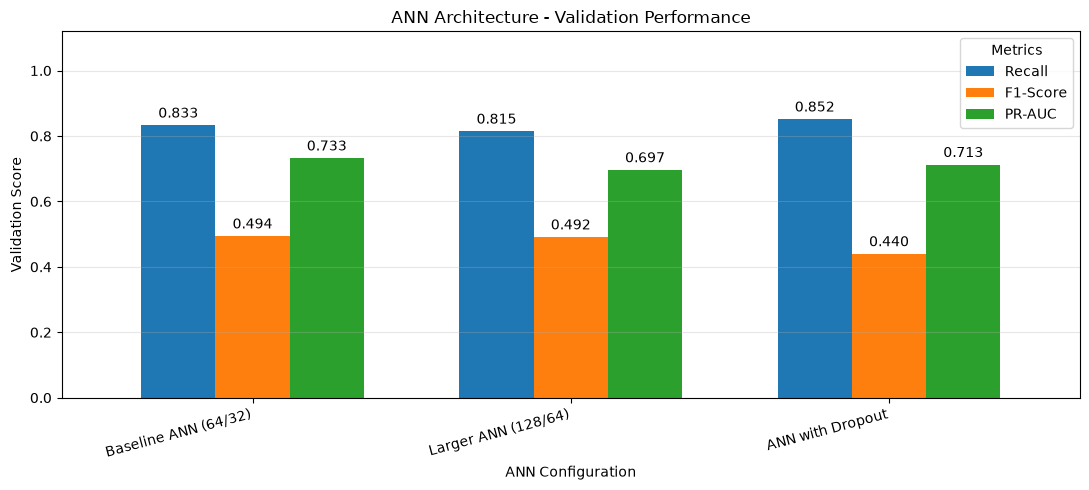

In [106]:

# Purpose: Compare ANN architecture configurations
# using Recall, F1-score and PR-AUC.

architecture_plot = ann_architecture_results.set_index(
    "Configuration"
)[["Recall", "F1-Score", "PR-AUC"]]

ax = architecture_plot.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("ANN Architecture - Validation Performance")
plt.xlabel("ANN Configuration")
plt.ylabel("Validation Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### 4.4 Controlled ANN Experiments — Results and Interpretation

The ANN optimization experiments investigated how learning rate, network architecture and Dropout regularization influence machine failure prediction.

#### 1. Learning Rate Experiment

Two learning rates, 0.001 and 0.0001, were evaluated using three random seeds (42, 52 and 62).

**Results:**

| Metric | Learning Rate 0.0001 | Learning Rate 0.001 |
|---|---:|---:|
| Accuracy (Mean) | 0.8813 | 0.9427 |
| Precision (Mean) | 0.2001 | 0.3521 |
| Recall (Mean) | 0.8395 | 0.8272 |
| F1-Score (Mean) | 0.3231 | 0.4937 |
| ROC-AUC (Mean) | 0.9464 | 0.9557 |
| PR-AUC (Mean) | 0.6007 | 0.7283 |

**Observations:**

- Learning rate 0.001 achieved a higher mean F1-score of 0.4937 compared with 0.3231.
- Mean PR-AUC improved from 0.6007 to 0.7283.
- Learning rate 0.0001 achieved slightly higher mean Recall (0.8395).
- The standard deviations were relatively small across the three runs.

**Finding:** Learning rate 0.001 provided better overall predictive performance across the evaluated metrics.

#### 2. ANN Architecture Experiment

Three ANN configurations were evaluated:

- Baseline ANN: 64/32 hidden neurons.
- Larger ANN: 128/64 hidden neurons.
- ANN with Dropout: 64/32 hidden neurons and Dropout rate 0.2.

**Results:**

| Configuration | Recall | F1-Score | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|
| Baseline ANN | 0.8333 | 0.4945 | 0.9561 | 0.7328 |
| Larger ANN | 0.8148 | 0.4916 | 0.9522 | 0.6968 |
| ANN with Dropout | 0.8519 | 0.4402 | 0.9639 | 0.7129 |

**Observations:**

- Increasing hidden neurons from 64/32 to 128/64 did not improve F1-score or PR-AUC.
- Dropout achieved the highest Recall (0.8519) and ROC-AUC (0.9639).
- However, Dropout reduced F1-score to 0.4402 compared with the baseline value of 0.4945.
- The baseline ANN achieved the highest F1-score and PR-AUC among the three configurations.

**Finding:** Increasing network complexity and applying Dropout did not consistently improve ANN performance.

#### Overall Experimental Conclusion

The learning-rate experiment demonstrated that 0.001 was more effective than 0.0001 for overall predictive performance.

The baseline 64/32 ANN architecture provided a better balance between Recall, F1-score and PR-AUC than the larger and Dropout configurations.

However, the architecture experiments were conducted as individual runs, whereas the learning-rate experiments used three random seeds. Therefore, architecture-related findings should be treated as observations rather than statistically established improvements.



### 4.5 ANN vs Traditional Machine Learning Comparison

This experiment compares traditional machine learning models with Artificial Neural Network configurations to evaluate their effectiveness in predicting machine failures.

**Traditional Machine Learning Models:**
- Logistic Regression
- Random Forest
- Tuned Random Forest with Random Oversampling

**Artificial Neural Network Models:**
- Baseline ANN
- ANN with Random Oversampling
- ANN with SMOTENC

**Evaluation Metrics:**

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- PR-AUC

Recall is particularly important because failing to identify a machine failure can result in unexpected equipment downtime.

F1-Score and PR-AUC are also important because the dataset contains a highly imbalanced target variable.

**Objective:** Compare the predictive performance of traditional ML and ANN models and identify which approach provides a better balance between failure detection and false alarms.


#### Consolidated model comparison

In [107]:

# Purpose: Compare traditional ML and ANN models using
# their previously recorded validation evaluation metrics.

ann_vs_traditional = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Category": "Traditional ML",
        "Accuracy": 0.8231,
        "Precision": 0.1433,
        "Recall": 0.8519,
        "F1-Score": 0.2453,
        "ROC-AUC": 0.8927,
        "PR-AUC": 0.4197
    },
    {
        "Model": "Random Forest",
        "Category": "Traditional ML",
        "Accuracy": 0.9750,
        "Precision": 0.6346,
        "Recall": 0.6111,
        "F1-Score": 0.6226,
        "ROC-AUC": 0.9524,
        "PR-AUC": 0.6866
    },
    {
        "Model": "Tuned Random Forest - ROS",
        "Category": "Traditional ML",
        "Accuracy": 0.9806,
        "Precision": 0.7347,
        "Recall": 0.6667,
        "F1-Score": 0.6990,
        "ROC-AUC": 0.9636,
        "PR-AUC": 0.7585
    },
    {
        "Model": "Baseline ANN",
        "Category": "ANN",
        "Accuracy": 0.9425,
        "Precision": 0.3516,
        "Recall": 0.8333,
        "F1-Score": 0.4945,
        "ROC-AUC": 0.9561,
        "PR-AUC": 0.7328
    },
    {
        "Model": "ANN - ROS",
        "Category": "ANN",
        "Accuracy": 0.9613,
        "Precision": 0.4574,
        "Recall": 0.7963,
        "F1-Score": 0.5811,
        "ROC-AUC": 0.9578,
        "PR-AUC": 0.7070
    },
    {
        "Model": "ANN - SMOTENC",
        "Category": "ANN",
        "Accuracy": 0.9637,
        "Precision": 0.4778,
        "Recall": 0.7963,
        "F1-Score": 0.5972,
        "ROC-AUC": 0.9566,
        "PR-AUC": 0.7212
    }
])

# Display models ordered by F1-score
display(
    ann_vs_traditional
    .sort_values("F1-Score", ascending=False)
    .reset_index(drop=True)
    .round(4)
)


,Model,Category,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Tuned Random Forest - ROS,Traditional ML,0.9806,0.7347,0.6667,0.6990,0.9636,0.7585
1,Random Forest,Traditional ML,0.9750,0.6346,0.6111,0.6226,0.9524,0.6866
2,ANN - SMOTENC,ANN,0.9637,0.4778,0.7963,0.5972,0.9566,0.7212
3,ANN - ROS,ANN,0.9613,0.4574,0.7963,0.5811,0.9578,0.7070
4,Baseline ANN,ANN,0.9425,0.3516,0.8333,0.4945,0.9561,0.7328
5,Logistic Regression,Traditional ML,0.8231,0.1433,0.8519,0.2453,0.8927,0.4197


#### Identify the best model for each metric

In [108]:

# Purpose: Identify the highest-performing model
# for each evaluation metric.

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

best_model_by_metric = pd.DataFrame([
    {
        "Metric": metric,
        "Best Model": ann_vs_traditional.loc[
            ann_vs_traditional[metric].idxmax(), "Model"
        ],
        "Best Score": ann_vs_traditional[metric].max()
    }
    for metric in comparison_metrics
])

display(best_model_by_metric.round(4))


,Metric,Best Model,Best Score
0,Accuracy,Tuned Random Forest - ROS,0.9806
1,Precision,Tuned Random Forest - ROS,0.7347
2,Recall,Logistic Regression,0.8519
3,F1-Score,Tuned Random Forest - ROS,0.6990
4,ROC-AUC,Tuned Random Forest - ROS,0.9636
5,PR-AUC,Tuned Random Forest - ROS,0.7585


###  Visualize Recall and F1-score comparison

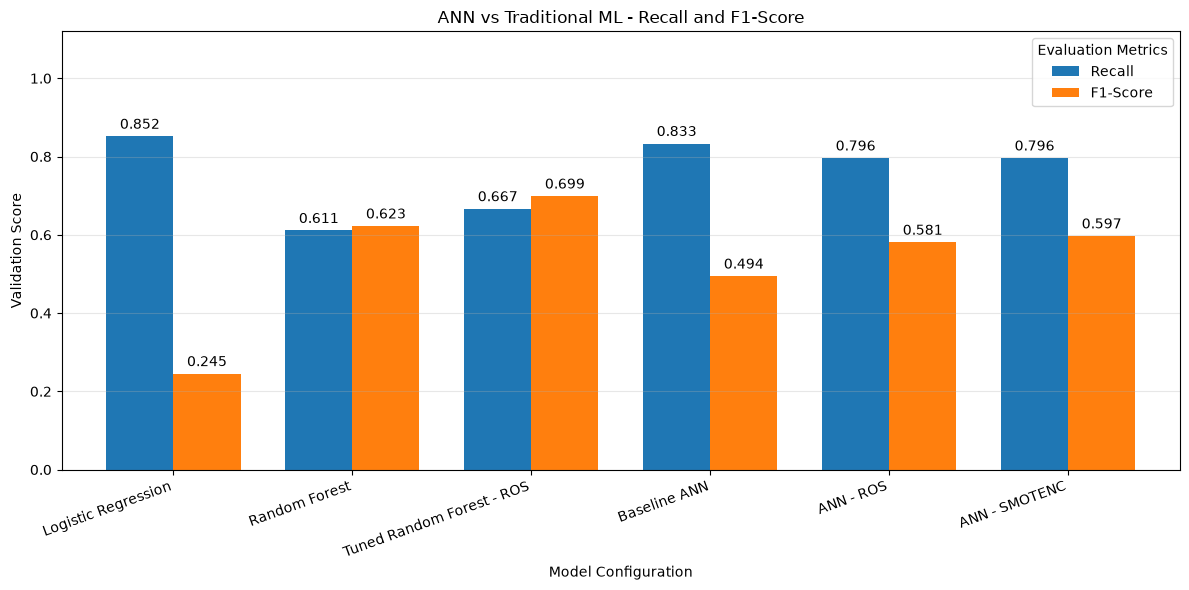

In [109]:

# Purpose: Compare failure detection capability and
# classification balance across traditional ML and ANN models.

comparison_plot = ann_vs_traditional.set_index("Model")[
    ["Recall", "F1-Score"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

# Display values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("ANN vs Traditional ML - Recall and F1-Score")
plt.xlabel("Model Configuration")
plt.ylabel("Validation Score")
plt.ylim(0, 1.12)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### Visualize PR-AUC comparison

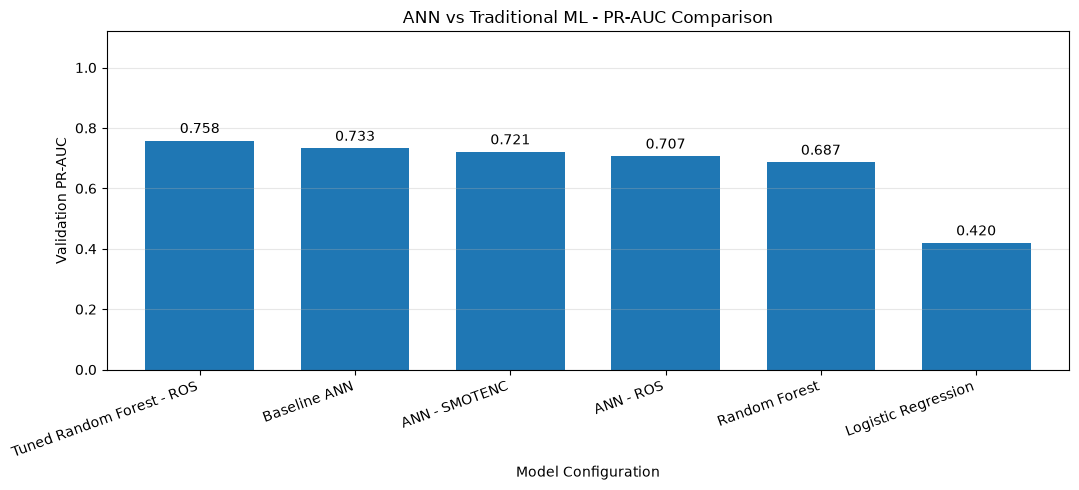

In [110]:

# Purpose: Compare model performance on the minority
# machine-failure class using PR-AUC.

pr_auc_plot = ann_vs_traditional.sort_values(
    by="PR-AUC",
    ascending=False
)

ax = pr_auc_plot.plot(
    x="Model",
    y="PR-AUC",
    kind="bar",
    figsize=(11, 5),
    legend=False,
    width=0.7
)

# Display values above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title("ANN vs Traditional ML - PR-AUC Comparison")
plt.xlabel("Model Configuration")
plt.ylabel("Validation PR-AUC")
plt.ylim(0, 1.12)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Phase 4.6 — Hypothesis Evaluation and Experimental Findings

In [111]:

# Purpose: Compare the strongest traditional ML and ANN
# configurations using their validation F1-score and PR-AUC.

best_traditional = (
    ann_vs_traditional[
        ann_vs_traditional["Category"] == "Traditional ML"
    ]
    .sort_values("F1-Score", ascending=False)
    .iloc[0]
)

best_ann = (
    ann_vs_traditional[
        ann_vs_traditional["Category"] == "ANN"
    ]
    .sort_values("F1-Score", ascending=False)
    .iloc[0]
)

family_comparison = pd.DataFrame([
    {
        "Model Family": "Traditional ML",
        "Best Model": best_traditional["Model"],
        "F1-Score": best_traditional["F1-Score"],
        "PR-AUC": best_traditional["PR-AUC"],
        "Recall": best_traditional["Recall"]
    },
    {
        "Model Family": "ANN",
        "Best Model": best_ann["Model"],
        "F1-Score": best_ann["F1-Score"],
        "PR-AUC": best_ann["PR-AUC"],
        "Recall": best_ann["Recall"]
    }
])

display(family_comparison.round(4))

print(
    "F1-Score difference:",
    round(best_traditional["F1-Score"] - best_ann["F1-Score"], 4)
)

print(
    "PR-AUC difference:",
    round(best_traditional["PR-AUC"] - best_ann["PR-AUC"], 4)
)


,Model Family,Best Model,F1-Score,PR-AUC,Recall
0,Traditional ML,Tuned Random Forest - ROS,0.6990,0.7585,0.6667
1,ANN,ANN - SMOTENC,0.5972,0.7212,0.7963


F1-Score difference: 0.1018
PR-AUC difference: 0.0373



#### Traditional ML vs ANN — Comparative Results

The best-performing model from each family was compared using validation metrics.

| Model Family | Best Model | F1-Score | PR-AUC | Recall |
|---|---|---:|---:|---:|
| Traditional ML | Tuned Random Forest - ROS | 0.6990 | 0.7585 | 0.6667 |
| ANN | ANN - SMOTENC | 0.5972 | 0.7212 | 0.7963 |

**Performance Differences:**

- F1-Score difference: 0.1018 in favor of Traditional ML.
- PR-AUC difference: 0.0373 in favor of Traditional ML.
- Recall difference: 0.1296 in favor of ANN.

**Observation:** Tuned Random Forest - ROS achieved better F1-Score and PR-AUC, while ANN - SMOTENC achieved higher Recall.


### Consolidated Experiment Summary

In [112]:
# Purpose: Summarize the major experiments conducted
# during Phase 2 and Phase 4.

experiment_summary = pd.DataFrame([
    {
        "Experiment": "Learning Rate",
        "Configurations": "0.001 vs 0.0001",
        "Best Configuration": "0.001",
        "Key Finding": "Higher mean F1-Score and PR-AUC"
    },
    {
        "Experiment": "ANN Architecture",
        "Configurations": "64/32 vs 128/64",
        "Best Configuration": "Baseline ANN (64/32)",
        "Key Finding": "Larger network did not improve F1-Score"
    },
    {
        "Experiment": "Dropout Regularization",
        "Configurations": "Dropout 0.0 vs 0.2",
        "Best Configuration": "Baseline ANN",
        "Key Finding": "Dropout increased Recall but reduced F1-Score"
    },
    {
        "Experiment": "Random Oversampling",
        "Configurations": "Original vs ROS",
        "Best Configuration": "Varies by model",
        "Key Finding": "Improved some model evaluation metrics"
    },
    {
        "Experiment": "SMOTENC",
        "Configurations": "Original vs SMOTENC",
        "Best Configuration": "ANN - SMOTENC for ANN F1-Score",
        "Key Finding": "ANN F1-Score improved over baseline"
    },
    {
        "Experiment": "Model Family Comparison",
        "Configurations": "Traditional ML vs ANN",
        "Best Configuration": "Tuned Random Forest - ROS",
        "Key Finding": "Higher F1-Score and PR-AUC"
    }
])

display(experiment_summary)

,Experiment,Configurations,Best Configuration,Key Finding
0,Learning Rate,0.001 vs 0.0001,0.001,Higher mean F1-Score and PR-AUC
1,ANN Architecture,64/32 vs 128/64,Baseline ANN (64/32),Larger network did not improve F1-Score
2,Dropout Regularization,Dropout 0.0 vs 0.2,Baseline ANN,Dropout increased Recall but reduced F1-Score
3,Random Oversampling,Original vs ROS,Varies by model,Improved some model evaluation metrics
4,SMOTENC,Original vs SMOTENC,ANN - SMOTENC for ANN F1-Score,ANN F1-Score improved over baseline
5,Model Family Comparison,Traditional ML vs ANN,Tuned Random Forest - ROS,Higher F1-Score and PR-AUC



#### 4.7 Experiment Summary and Conclusion

The controlled experiments evaluated the influence of class imbalance handling, hyperparameter selection, learning rate and ANN architecture on machine failure prediction.

**Major Findings:**

- Learning rate 0.001 achieved better mean F1-Score and PR-AUC than 0.0001.
- Increasing ANN architecture complexity did not improve the F1-Score.
- Dropout increased Recall but reduced F1-Score.
- Random Oversampling improved selected model evaluation metrics.
- SMOTENC improved the ANN F1-Score from 0.4945 to 0.5972.
- Tuned Random Forest with Random Oversampling achieved the highest F1-Score (0.6990) and PR-AUC (0.7585) among the compared models.

**Final Experimental Conclusion:**

The experiments demonstrate that model performance depends on the algorithm, class imbalance strategy and hyperparameter configuration.

Although ANN achieved competitive failure detection Recall, Tuned Random Forest with Random Oversampling provided a better balance between Precision, Recall, F1-Score and PR-AUC.

Therefore, the experimental findings favor Tuned Random Forest with Random Oversampling for this predictive maintenance use case.

These findings are based on the current dataset and validation setup. Further evaluation on real operational data is necessary before deployment.

--------------------------------------------------------------------------------------------------------------


# Phase 5 — Business Interpretation and Recommendations

### 5.1 Business Objective

The objective of this phase is to translate machine failure predictions into actionable maintenance decisions for smart manufacturing environments.

The selected model, **Tuned Random Forest with Random Oversampling**, will be used to identify machines that may be at risk of failure.

The business interpretation focuses on:

- Identifying machines with a high probability of failure.
- Prioritizing machines for preventive inspection.
- Reducing unexpected equipment downtime.
- Understanding the operational impact of false alarms and missed failures.
- Recommending appropriate maintenance actions based on predicted risk.

**Business Goal:**

Move from reactive maintenance to proactive, risk-based maintenance by identifying potential machine failures before they occur.



### 5.2 Machine Failure Risk Categorization

The selected Tuned Random Forest model generates a failure probability for each machine observation.

To support maintenance planning, predicted probabilities are divided into three operational risk categories.

| Risk Category | Failure Probability | Recommended Action |
|---|---|---|
| Low Risk | Below 0.10 | Continue routine monitoring. |
| Medium Risk | 0.10 to below 0.30 | Increase monitoring and review sensor readings. |
| High Risk | 0.30 or above | Prioritize machine inspection and maintenance review. |

**Operational Decision Threshold: 0.15**

The selected decision threshold of 0.15 was obtained through validation-based cost analysis.

Therefore, medium-risk observations with a predicted failure probability of 0.15 or higher will also be included in the inspection queue.

**Objective:** Convert model-generated failure probabilities into actionable maintenance priorities.

*Note: These are proposed operational risk bands, not calibrated guarantees of machine failure. They should be validated with maintenance experts before deployment.*


### Assign Machine Failure Risk Categories

In [113]:
# Purpose: Categorize machine observations into Low, Medium
# and High risk based on predicted failure probabilities.

import numpy as np
import pandas as pd

# Create a risk assessment DataFrame
risk_assessment = X_test.copy()

risk_assessment["Actual Failure"] = np.asarray(y_test)
risk_assessment["Failure Probability"] = y_rf_test_prob
risk_assessment["Predicted Failure"] = y_rf_test_pred

# Assign operational risk categories
risk_assessment["Risk Level"] = pd.cut(
    risk_assessment["Failure Probability"],
    bins=[-np.inf, 0.10, 0.30, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

# Apply the selected inspection threshold
risk_assessment["Inspection Required"] = (
    risk_assessment["Failure Probability"] >= FINAL_THRESHOLD
)

# Sort observations by predicted failure probability
risk_assessment = risk_assessment.sort_values(
    by="Failure Probability",
    ascending=False
)

display(risk_assessment.head(10))

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Actual Failure,Failure Probability,Predicted Failure,Risk Level,Inspection Required
1391,L,298.9,310.2,2737,8.8,142,1,0.989990,1,High,True
7011,L,300.5,310.5,2633,12.2,17,1,0.961537,1,High,True
4427,M,302.4,310.1,1379,48.9,107,1,0.949375,1,High,True
4449,M,302.4,310.3,1378,54.3,165,1,0.945905,1,High,True
4495,L,302.6,310.4,1359,57.2,67,1,0.945344,1,High,True
4661,L,303.3,311.3,1350,48.1,32,1,0.919206,1,High,True
2444,L,299.2,308.6,1267,68.2,76,1,0.909685,1,High,True
4270,L,302.6,310.9,1331,52.0,154,1,0.909552,1,High,True
7997,M,301.0,312.2,2710,9.7,143,1,0.908341,1,High,True
6078,L,300.8,310.7,1339,59.1,203,1,0.907912,1,High,True


### 5.3 Risk Assessment — Initial Observations

The tuned Random Forest model was used to estimate machine failure probabilities on the test dataset. These probabilities were converted into Low, Medium, and High risk categories.

**Observations from the top 10 highest-risk machines:**

- All 10 observations belong to the actual failure class.
- All 10 were correctly predicted as failures.
- Their predicted failure probabilities range from approximately 0.908 to 0.990.
- All observations were categorized as High Risk.
- All 10 were flagged for inspection based on the selected decision threshold of 0.15.

**Business Interpretation:**

Machines with high predicted failure probabilities should receive priority for maintenance inspection. This risk-based approach can help maintenance teams prioritize inspections instead of treating every machine equally.

These observations demonstrate the model's ranking of high-risk cases; they do not establish that every high-risk prediction will result in an actual failure.

### Risk Category Distribution

In [114]:
# Purpose: Summarize the number of machines in each risk category
# and identify how many machines require inspection.

risk_summary = (
    risk_assessment
    .groupby("Risk Level", observed=False)
    .agg(
        Machine_Count=("Failure Probability", "count"),
        Actual_Failures=("Actual Failure", "sum"),
        Predicted_Failures=("Predicted Failure", "sum"),
        Inspection_Required=("Inspection Required", "sum"),
        Average_Failure_Probability=("Failure Probability", "mean")
    )
    .reset_index()
)

risk_summary["Machine_Percentage"] = (
    risk_summary["Machine_Count"] / len(risk_assessment) * 100
)

display(risk_summary.round(4))

print(
    "Total machines requiring inspection:",
    int(risk_assessment["Inspection Required"].sum())
)

,Risk Level,Machine_Count,Actual_Failures,Predicted_Failures,Inspection_Required,Average_Failure_Probability,Machine_Percentage
0,Low,1805,5,0,0,0.0055,90.25
1,Medium,88,10,48,48,0.1792,4.40
2,High,107,53,107,107,0.5933,5.35


Total machines requiring inspection: 155


### 5.4 Risk Distribution — Business Interpretation

The test dataset contains 2,000 machine observations distributed across three predicted risk categories.

| Risk Level | Machines | Percentage | Actual Failures | Inspection Required |
|---|---:|---:|---:|---:|
| Low | 1,805 | 90.25% | 5 | 0 |
| Medium | 88 | 4.40% | 10 | 48 |
| High | 107 | 5.35% | 53 | 107 |

**Key Findings:**

- 90.25% of machines were categorized as Low Risk.
- All 107 High-risk machines were flagged for inspection.
- 48 Medium-risk machines crossed the selected inspection threshold of 0.15.
- A total of 155 machines (7.75%) were selected for inspection.
- Five actual failures were categorized as Low Risk and were not selected for inspection.

**Business Interpretation:**

The risk categorization helps maintenance teams prioritize a smaller group of machines for inspection. High-risk machines should receive immediate attention, while Medium-risk machines crossing the operational threshold should be scheduled for inspection.

However, the five failures in the Low-risk category highlight the possibility of missed failures. The risk categories and inspection threshold should therefore be reviewed with maintenance experts before operational deployment.

#### Sensor Parameter Comparison

In [115]:
# Purpose: Compare machine operating parameters between normal
# and failed machines to identify patterns for maintenance review.

sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

sensor_comparison = (
    risk_assessment
    .groupby("Actual Failure")[sensor_features]
    .agg(["mean", "median"])
    .round(2)
)

sensor_comparison.index = ["Normal Machines", "Failed Machines"]

display(sensor_comparison)

Air temperature [K]         Process temperature [K]         \
                               mean  median                    mean median   
Normal Machines              299.98  300.00                  310.00  310.1   
Failed Machines              300.74  301.55                  310.14  310.4   

                Rotational speed [rpm]         Torque [Nm]         \
                                  mean  median        mean median   
Normal Machines                1538.45  1507.0       39.56   39.9   
Failed Machines                1479.57  1359.0       50.16   54.3   

                Tool wear [min]         
                           mean median  
Normal Machines          107.46  110.5  
Failed Machines          153.32  164.5

### 5.5 Sensor Pattern Analysis — Business Interpretation

The sensor parameters of normal and failed machines were compared using their mean and median values.

**Key Observations:**

- **Torque:** Failed machines recorded a higher mean torque of 50.16 Nm compared with 39.56 Nm for normal machines.
- **Tool Wear:** Failed machines showed higher mean tool wear of 153.32 minutes compared with 107.46 minutes.
- **Rotational Speed:** Failed machines recorded a lower mean rotational speed of 1479.57 rpm compared with 1538.45 rpm.
- **Air Temperature:** Failed machines showed a slightly higher mean air temperature.
- **Process Temperature:** The difference in mean process temperature between the two groups was relatively small.

**Business Interpretation:**

Higher torque and tool wear, along with lower rotational speed, are useful patterns for further investigation when assessing machine failure risk.

Maintenance teams could monitor these parameters and prioritize machines exhibiting unusual combinations of readings.

These findings represent associations observed in the test dataset. They do not establish that any individual sensor parameter directly causes machine failure.

### 5.6 Predictive Maintenance Recommendations

Based on the model's risk categorization and observed sensor patterns, the following maintenance actions are recommended.

| Risk Category / Observation | Recommended Maintenance Action |
|---|---|
| High Risk | Prioritize immediate machine inspection and investigate potential failure conditions. |
| Medium Risk (probability ≥ 0.15) | Add machines to the maintenance inspection queue and schedule preventive checks. |
| Low Risk | Continue routine monitoring and scheduled preventive maintenance. |
| High Torque | Inspect load conditions, mechanical components, and operating parameters. |
| High Tool Wear | Monitor tool condition and consider timely tool replacement. |
| Lower Rotational Speed | Investigate abnormal speed variations and possible operating issues. |

**Operational Recommendations:**

- Use model-generated failure probabilities to prioritize maintenance inspections.
- Monitor torque, tool wear, and rotational speed for unusual operating patterns.
- Review false negatives regularly to identify failures that the model may miss.
- Record inspection outcomes and maintenance actions to support future model improvement.
- Keep maintenance decisions under human supervision rather than relying entirely on automated predictions.

**Expected Business Benefits:**

- Better prioritization of maintenance resources.
- Earlier identification of potentially failing machines.
- Reduced dependence on purely reactive maintenance.
- Improved visibility into machine-level failure risk.

These recommendations are proposed actions based on the model's predictions and observed dataset patterns. Their actual operational benefits must be evaluated through a controlled pilot.

### 5.7 Model Limitations and Deployment Considerations

Although the tuned Random Forest model demonstrated promising predictive performance, several limitations must be considered before real-world deployment.

**Dataset Limitations:**

- The AI4I 2020 dataset is synthetic and may not fully represent real industrial operating conditions.
- The dataset does not provide continuous time-series histories for individual machines.
- Real manufacturing environments may contain sensor noise, missing readings, changing operating conditions, and equipment-specific variations.

**Model Limitations:**

- The model may produce false positives, resulting in unnecessary inspections.
- False negatives may cause actual machine failures to go undetected.
- The observed training and validation performance gap indicates potential overfitting.
- Predicted probabilities should not automatically be interpreted as calibrated real-world failure probabilities.
- Sensor patterns and model feature relationships do not establish causal relationships.

**Deployment Considerations:**

- Validate the model using real industrial machine data before deployment.
- Evaluate probability calibration and decision thresholds with maintenance experts.
- Monitor model performance and data drift after deployment.
- Retrain the model when operating conditions or failure patterns change.
- Keep human experts involved in inspection and maintenance decisions.

**Conclusion:**

The developed model should be considered a decision-support system for prioritizing machine inspections, not an autonomous maintenance or machine-shutdown system. A controlled pilot using real manufacturing data is recommended before production deployment.

### 5.8 Overall Business Conclusion

This project developed a machine failure prediction system using the AI4I 2020 Predictive Maintenance dataset.

Multiple machine learning and deep learning approaches were evaluated, including Logistic Regression, Random Forest, and Artificial Neural Networks.

**Final Model Selection:**

The tuned Random Forest model with Random Oversampling was selected as the final candidate based on its validation performance and ability to identify machine failures.

At the selected decision threshold of 0.15, its test performance was:

| Evaluation Metric | Test Result |
|---|---:|
| Accuracy | 0.9485 |
| Precision | 0.3871 |
| Recall | 0.8824 |
| F1-Score | 0.5381 |
| ROC-AUC | 0.9639 |
| PR-AUC | 0.7605 |

**Business Findings:**

- The model identified 60 out of 68 actual machine failures in the test dataset.
- Eight actual failures were missed.
- A total of 155 machines were flagged for inspection.
- Sensor comparisons highlighted differences in torque, tool wear, and rotational speed between normal and failed machines.
- Risk categorization provides a structured way to prioritize maintenance inspections.

**Final Recommendation:**

The tuned Random Forest model is a promising candidate for a controlled predictive maintenance pilot. Before real-world deployment, it requires validation using actual industrial data, probability calibration, threshold evaluation, and continuous performance monitoring.

The overall objective is to move from reactive maintenance toward a more proactive, data-driven maintenance strategy.

In [116]:
# Purpose: Identify available DataFrames and their dimensions
# before exporting the assessment deliverables.

available_dataframes = pd.DataFrame([
    {
        "Variable": name,
        "Rows": value.shape[0],
        "Columns": value.shape[1],
        "Column Names": list(value.columns)
    }
    for name, value in globals().items()
    if isinstance(value, pd.DataFrame)
])

display(available_dataframes)

,Variable,Rows,Columns,Column Names
0,df,10000,14,"[UDI, Product ID, Type, Air temperature [K], P..."
1,_1,5,14,"[UDI, Product ID, Type, Air temperature [K], P..."
2,target_summary,2,2,"[Count, Percentage]"
3,outliers,0,14,"[UDI, Product ID, Type, Air temperature [K], P..."
4,outlier_summary,5,5,"[Feature, Lower Bound, Upper Bound, Outlier Co..."
...,...,...,...,...
61,family_comparison,2,5,"[Model Family, Best Model, F1-Score, PR-AUC, R..."
62,experiment_summary,6,4,"[Experiment, Configurations, Best Configuratio..."
63,risk_assessment,2000,11,"[Type, Air temperature [K], Process temperatur..."
64,risk_summary,3,7,"[Risk Level, Machine_Count, Actual_Failures, P..."


In [117]:
# Purpose: Identify DataFrames related to model comparison
# and experimental results.

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        if any(keyword in name.lower() for keyword in ["model", "comparison", "experiment"]):
            print(f"\nDataFrame: {name}")
            print(f"Shape: {value.shape}")
            print(f"Columns: {list(value.columns)}")


DataFrame: comparison_df
Shape: (4, 5)
Columns: ['Feature', 'Group', 'Records', 'Failures', 'Failure Rate (%)']

DataFrame: failure_comparison
Shape: (5, 2)
Columns: ['No Failure', 'Failure']

DataFrame: imbalance_comparison
Shape: (9, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']

DataFrame: comparison_plot
Shape: (6, 2)
Columns: ['Recall', 'F1-Score']

DataFrame: rf_experiment_comparison
Shape: (4, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']

DataFrame: ann_lr_comparison
Shape: (6, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']

DataFrame: ann_architecture_comparison
Shape: (3, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']

DataFrame: selected_model_results
Shape: (5, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']

DataFrame: model_data
Shape: (17, 9)
Columns: ['Mode

In [119]:
# Purpose: Display all DataFrame names related to model evaluation
# and experiments without truncating their contents.

for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        if any(keyword in name.lower() for keyword in [
            "model", "experiment", "comparison", "summary"
        ]):
            print(f"{name}: {value.shape}")

target_summary: (2, 2)
outlier_summary: (5, 5)
comparison_df: (4, 5)
directional_summary: (6, 5)
type_summary: (3, 4)
failure_comparison: (5, 2)
split_summary: (2, 4)
validation_summary: (2, 3)
imbalance_comparison: (9, 7)
comparison_plot: (6, 2)
rf_experiment_comparison: (4, 7)
ann_lr_comparison: (6, 7)
ann_lr_summary: (2, 12)
ann_architecture_comparison: (3, 7)
selected_model_results: (5, 7)
model_data: (17, 9)
threshold_comparison_df: (2, 9)
rf_reliability_comparison: (2, 7)
validation_test_comparison: (2, 6)
best_model_by_metric: (6, 3)
family_comparison: (2, 5)
experiment_summary: (6, 4)
risk_summary: (3, 7)
sensor_comparison: (2, 10)


In [120]:
# Purpose: Inspect the final model comparison and experiment
# summary tables before exporting assessment deliverables.

print("MODEL COMPARISON DATA")
display(selected_model_results)

print("\nEXPERIMENT RESULTS DATA")
display(experiment_summary)

MODEL COMPARISON DATA


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.823125,0.143302,0.851852,0.245333,0.892734,0.419706
1,Random Forest - Tuned ROS,0.980625,0.734694,0.666667,0.699029,0.963628,0.758543
2,ANN,0.942500,0.351562,0.833333,0.494505,0.956147,0.732775
3,ANN - ROS,0.961250,0.457447,0.796296,0.581081,0.957836,0.707028
4,ANN - SMOTENC,0.963750,0.477778,0.796296,0.597222,0.956626,0.721177



EXPERIMENT RESULTS DATA


,Experiment,Configurations,Best Configuration,Key Finding
0,Learning Rate,0.001 vs 0.0001,0.001,Higher mean F1-Score and PR-AUC
1,ANN Architecture,64/32 vs 128/64,Baseline ANN (64/32),Larger network did not improve F1-Score
2,Dropout Regularization,Dropout 0.0 vs 0.2,Baseline ANN,Dropout increased Recall but reduced F1-Score
3,Random Oversampling,Original vs ROS,Varies by model,Improved some model evaluation metrics
4,SMOTENC,Original vs SMOTENC,ANN - SMOTENC for ANN F1-Score,ANN F1-Score improved over baseline
5,Model Family Comparison,Traditional ML vs ANN,Tuned Random Forest - ROS,Higher F1-Score and PR-AUC


In [121]:
# Purpose: Export the final model comparison and experiment
# summary tables as assessment deliverables.

selected_model_results.to_csv(
    "model_comparison.csv",
    index=False
)

experiment_summary.to_csv(
    "experiment_results.csv",
    index=False
)

print("Assessment CSV files exported successfully!")

print("\nGenerated files:")
print("1. model_comparison.csv")
print("2. experiment_results.csv")

Assessment CSV files exported successfully!

Generated files:
1. model_comparison.csv
2. experiment_results.csv


In [122]:
# Purpose: Verify that both assessment CSV files exist
# and can be loaded successfully.

import os
import pandas as pd

export_files = [
    "model_comparison.csv",
    "experiment_results.csv"
]

for file_name in export_files:
    if os.path.exists(file_name):
        verification_df = pd.read_csv(file_name)

        print(f"\n{file_name}")
        print(f"File size: {os.path.getsize(file_name)} bytes")
        print(f"Shape: {verification_df.shape}")
        print("Status: Verified successfully")
    else:
        print(f"{file_name}: File not found")


model_comparison.csv
File size: 640 bytes
Shape: (5, 7)
Status: Verified successfully

experiment_results.csv
File size: 612 bytes
Shape: (6, 4)
Status: Verified successfully
